# Fourier control of FerroSim: curl, waveform simplicity, and disorder

This notebook reproduces the original fixed-defect-map study, then analyzes
**ten new random placements of the same 19 defect vectors**. Every map is
searched with four pipelines, three optimizer seeds, and a common budget of
**64 initial observations + 32 generations × 32 new observations = 1,088
attempts per run**. All rewards shown below are physical simulator results.

The two questions are distinct: how much curl can we obtain, and how simple
a waveform can retain nearly all of that curl? We retain observations from
every generation, including the cold start, when constructing empirical
Pareto fronts. The cross-disorder chapter then asks whether a useful waveform
transfers between maps or needs adaptation to a particular defect layout.

**Default execution:** verify frozen input hashes, load recorded physical
observations, and recompute numerical summaries, tables, and figures. This is
archived-result reproduction and makes **zero new simulator queries**.
Optional fresh optimization is an explicit switch below; archived rewards
are never described as newly simulated results.

The model, control renderer, four search implementations, and exact numerical
protocol are local to this repository: [oracle.py](oracle.py),
[representation.py](representation.py), [run_benchmark.py](run_benchmark.py),
[protocol.json](protocol.json), and [study_analysis.py](study_analysis.py).
Install the pinned environment from `requirements.txt` before running all
cells. The notebook locates its project directory from either this folder or
the repository root.

In [1]:
from pathlib import Path
import os
import sys
import json
import subprocess
import hashlib

# Keep CPU linear algebra deterministic and avoid nested thread oversubscription.
for name in ("OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[name] = "1"

candidates = [Path.cwd(), Path.cwd() / "curl/Fourier_descriptors"]
candidates += [parent / "curl/Fourier_descriptors" for parent in Path.cwd().parents]
ROOT = next((p.resolve() for p in candidates if (p / "study_analysis.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Run from Fourier_descriptors or the FerroNet_Optimization repository root.")
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
import representation as rep
import study_analysis as sa

pd.set_option("display.max_columns", 18)
pd.set_option("display.max_colwidth", 64)
pd.set_option("display.float_format", lambda value: f"{value:.6f}")

def read_json(relative_path):
    return json.loads((ROOT / relative_path).read_text())

def show_figure(relative_path, width=1150):
    path = ROOT / relative_path
    if not path.is_file():
        raise FileNotFoundError(f"Required analysis figure is missing: {path}")
    display(Image(filename=str(path), width=width))

def run_script(script, *arguments):
    command = [sys.executable, str(ROOT / script), *map(str, arguments)]
    result = subprocess.run(command, cwd=ROOT, env=os.environ.copy(), text=True,
                            stdout=subprocess.PIPE, stderr=subprocess.STDOUT)
    print(result.stdout[-6000:])
    result.check_returncode()

print(f"Project: {ROOT.name}; Python {sys.version.split()[0]}")

Project: Fourier_descriptors; Python 3.12.14


In [2]:
RUN_SIMULATIONS = False
RUN_FULL_REVALIDATION = RUN_SIMULATIONS  # Fresh runs refine their own winners and repeat transfer.
ALLOW_PARTIAL = False          # Development only; the delivered notebook requires all 132 runs.
SHOW_SUPPLEMENTARY = False     # Additional figures are still regenerated and exported.
WORKERS = 6

# Fresh directories keep recomputed searches separate from the frozen release.
# Re-running with RUN_SIMULATIONS=True resumes this directory; completed runs are skipped.
FRESH_BASELINE = ROOT / "reproduction_runs/baseline"
FRESH_ENSEMBLE = ROOT / "reproduction_runs/disorder_ensemble"

## 1. Verify the inputs and execution mode

Hash verification uses a manifest committed **before** notebook execution.
Replaying the notebook never silently replaces that manifest. The check
covers source, protocol, original and new observation archives, defect maps,
and archived numerical validations. The ensemble loader separately checks
map identity, protocol source hashes, contiguous attempt ordering, and
consistency of the primary validity flag with the numerical and native guard
flags. Generation-zero arrays must agree across the four methods for each
paired seed.

The optional simulation branch first reruns all 12 original-map runs, then
invokes the frozen study supervisor for all 120 ensemble runs. On empty
reproduction directories it performs new optimization; on partly completed
ones it resumes. The original-map chapter and ensemble chapter then use
those fresh directories. Frozen release results remain a separate numerical
comparison and validation reference. No optimizer settings are tuned after
observing the new maps. Exact cross-platform equality is reported if it
occurs, not assumed.

In [3]:
integrity = sa.verify_integrity(ROOT, required=not ALLOW_PARTIAL)
protocol = read_json("protocol.json")
display(pd.DataFrame([{
    "input_hashes_verified": integrity.get("verified", False),
    "files_verified": integrity.get("verified_files", 0),
    "new_disorder_maps": len(protocol["disorder_ids"]),
    "optimizer_seeds": protocol["search_seeds"],
    "methods": len(protocol["methods"]),
    "generations": protocol["generations"],
    "observations_per_run": protocol["observations_per_method_seed"],
}]))
for filename, expected in protocol["core_source_sha256"].items():
    assert sa.sha256(ROOT / filename) == expected, f"Frozen source changed: {filename}"

if RUN_SIMULATIONS:
    print("First: recompute the original fixed-map study, all four methods and three seeds.")
    from concurrent.futures import ThreadPoolExecutor
    def run_original_seed(seed):
        run_script("run_benchmark.py", "--methods", "all", "--seeds", seed,
                   "--generations", 32, "--out", FRESH_BASELINE,
                   "--defects", ROOT / "data/disorders/baseline.npy", "--disorder-id", "baseline_fixed",
                   "--no-save-final-p", "--oracle-threads", 1, "--resume")
    with ThreadPoolExecutor(max_workers=min(WORKERS, len(protocol["search_seeds"]))) as executor:
        list(executor.map(run_original_seed, protocol["search_seeds"]))
    print("Next: recompute the ten-map ensemble using the frozen supervisor.")
    run_script("run_study.py", "--maps", ROOT / "data/disorders/manifest.json",
               "--protocol", ROOT / "protocol.json", "--out", FRESH_ENSEMBLE,
               "--workers", WORKERS, "--resume")
    ACTIVE_BASELINE = FRESH_BASELINE
    ACTIVE_ENSEMBLE = FRESH_ENSEMBLE
    STUDY_FIGURES = ROOT / "figures/recomputed_study"
    display(Markdown("**Mode: newly computed or resumed optimization.** Analysis below reads the reproduction directory."))
else:
    ACTIVE_BASELINE = ROOT / "data/baseline"
    ACTIVE_ENSEMBLE = ROOT / "data/disorder_ensemble"
    STUDY_FIGURES = ROOT / "figures/study"
    message = ("**Mode: archived search observations with explicitly requested new validation queries.**"
               if RUN_FULL_REVALIDATION else "**Mode: archived-result reproduction. No new simulator calls are made.**")
    display(Markdown(message))

if RUN_FULL_REVALIDATION:
    VALIDATION_ROOT = ROOT / "reproduction_runs/validation"
    BASELINE_PHYSICS = ROOT / "figures/recomputed_baseline_physics"
    run_script("validate_finalists.py", "--results", ACTIVE_BASELINE,
               "--output", VALIDATION_ROOT / "baseline")
    run_script("validate_disorder_study.py", "--results", ACTIVE_ENSEMBLE,
               "--manifest", ROOT / "data/disorders/manifest.json", "--output", VALIDATION_ROOT)
    from summarize_disorder_validation import summarize as summarize_validation
    summarize_validation(VALIDATION_ROOT)  # Pure postprocessing of the newly refined states.
    display(Markdown("**Numerical refinement and transfer have been recomputed for the active controls.**"))
else:
    VALIDATION_ROOT = ROOT / "validation"
    BASELINE_PHYSICS = ROOT / "figures/baseline_physics"
if RUN_SIMULATIONS:
    fresh_integrity = sa.freeze_or_verify_reproduction(
        ROOT, FRESH_ENSEMBLE, FRESH_BASELINE,
        validation_root=VALIDATION_ROOT if RUN_FULL_REVALIDATION else None)
    display(pd.DataFrame(fresh_integrity["comparison_to_archived_release"]))

,input_hashes_verified,files_verified,new_disorder_maps,optimizer_seeds,methods,generations,observations_per_run
0,True,914,10,"[0, 1, 2]",4,32,1088


**Mode: archived-result reproduction. No new simulator calls are made.**

## 2. The waveform and the optimization problem

The applied scalar field is spatially uniform and points in the x direction. On the driven interval
\(u=t/T\in[0,1]\),

\[
  \frac{E(t)}{E_c}=\sum_{k=1}^{34}a_k\sin(k\pi u),\qquad
  \sum_{k=1}^{34}k a_k=0,\qquad
  \sum_{k=1}^{34}(-1)^k k a_k=0.
\]

These two linear slope constraints leave **32 independent coefficients**.
The endpoints and endpoint slopes are zero. The simulator receives 900 drive
samples followed by a 50-sample zero-field hold. Neither amplitude nor
absolute slew rate is bounded. A finite sine series also fixes the even
endpoint derivatives to zero; that geometry differs from a spline basis.

The reward is the sum of absolute spatial curl of the final polarization,
evaluated with the simulator's periodic central differences after the hold:

\[
  R=\sum_{i,j}\left|\partial_x P_y(i,j)-\partial_y P_x(i,j)\right|.
\]

The existing native \(|P|=10\) guard and numerical integration status determine
whether a trajectory is valid; all attempted trajectories remain budgeted.
The primary complexity
\(C_{2\%}\) counts extrema whose prominence is at least 2% of the actual
waveform's peak-to-peak range, on 4,097 rendering points. We also report raw,
1%, and 5% extrema counts. A waveform with \(C_{2\%}=1\) can therefore have
tiny additional raw extrema; the strict \(C_{raw}\leq1\) comparison below
answers a different simplicity question. Here “resolved” means above the
specified prominence threshold. The raw count includes every local maximum
and minimum found on the same sampling grid without a prominence cutoff;
selected controls also receive an independent stationary-root check. One
prominent extremum therefore does not establish a literally single-turn
waveform.

All four pipelines use the same DKL surrogate, the same acquisition selector,
512 candidates from the named proposer, and 64 additional common-prior
candidates. Each generation evaluates 24 UCB selections, four uncertainty
selections, and four reserved common-exploration selections. The generation
cost is 32 physical attempts for every pipeline. These are concrete
implementations of GA, GFlowNet, continuous guided diffusion, and quality
diversity proposals, with the limitations of their implementations recorded
in the source and provenance audit. The diffusion implementation is a
continuous adaptation, not a reproduction of a named discrete-sequence
method.

In [4]:
import validate_representation as geometry
math_audit = geometry.mathematical_checks()
display(pd.DataFrame([{
    "free_coordinates": rep.DIM,
    "physical_sine_amplitudes": len(rep.HARMONICS),
    "drive_duration": rep.DRIVE_DURATION,
    "max_cycles_per_drive": rep.HARMONICS[-1] / 2,
    "amplitude_bound": rep.specification()["amplitude_bound"],
    "absolute_slew_bound": rep.specification()["absolute_slew_bound"],
}]))
display(math_audit)

,free_coordinates,physical_sine_amplitudes,drive_duration,max_cycles_per_drive,amplitude_bound,absolute_slew_bound
0,32,34,2.999166,17.000000,None,None


{'random_seed': 117,
 'waveforms_checked': 66,
 'N_orthogonality_max_abs_error': 1.6653345369377348e-15,
 'slope_constraint_matrix_max_abs_error': 7.310124727766265e-15,
 'M_condition': 2.4852506087385424,
 'render_basis_conditions': {'96': 1.000000000000002,
  '900': 1.0000000000000013,
  '4097': 1.000000000000001},
 'render_gram_max_abs_errors': {'96': 7.121388666764681e-15,
  '900': 5.684341886080802e-14,
  '4097': 2.4158453015843406e-13},
 'raw_endpoint_value_max_abs': 1.378200262540243e-12,
 'raw_endpoint_u_slope_max_abs': 5.002220859751105e-12,
 'raw_endpoint_u_curvature_max_abs': 1.0163856019502276e-08,
 'normalized_endpoint_residuals': {'value': 1.5143659572797934e-15,
  'slope': 1.4772636326034e-16,
  'curvature': 2.9545012442621653e-15},
 'sampled_endpoints_exact_zero': True,
 'full_coefficient_reconstruction_max_abs_error': 3.410605131648481e-13,
 'continuous_RMS_relative_error': 6.029155041345696e-16,
 'sampled_RMS_relation_relative_error': 6.029523020536208e-16,
 'unit_fir

### Recompute all archive analyses

This cell retains the original row order and writes complete scalar
observation tables, full historical fronts, front histories at generations
0, 1, 2, 3, 4, 8, 16, and 32, selected control coefficients, and sampled
waveforms. The final mode requires 12 original-map runs and 120 new-map runs,
all of length 1,088. Failed or guarded observations remain in the attempt
count but are excluded from reward maxima and Pareto fronts.

In [5]:
summary = sa.analyze_study(
    ROOT, allow_partial=ALLOW_PARTIAL, verify=not ALLOW_PARTIAL,
    output_dir=STUDY_FIGURES if RUN_SIMULATIONS else None,
    ensemble_root=ACTIVE_ENSEMBLE, baseline_root=ACTIVE_BASELINE, validation_dir=VALIDATION_ROOT,
)
TABLES = ROOT / summary["tables_directory"]
study_prefix = str(STUDY_FIGURES.relative_to(ROOT))
def study_figure(name):
    show_figure(f"{study_prefix}/{name}.png")
def study_table(name):
    return pd.read_csv(TABLES / f"{name}.csv")

run_summary = study_table("run_summary")
method_summary = study_table("method_by_disorder")
selected = study_table("selected_controls")
observations = pd.read_csv(TABLES / "observations.csv.gz")
assert summary["new_physics_calls"] == 0
if not ALLOW_PARTIAL:
    assert summary["completeness"]["complete"]
    assert summary["completeness"]["baseline_runs"] == 12
    assert summary["completeness"]["ensemble_runs"] == 120
    assert len(observations) == 143616
display(pd.DataFrame([summary["completeness"]]).drop(columns=["missing", "incomplete"]))

,complete,expected_runs,loaded_runs,observations,baseline_runs,ensemble_runs
0,True,132,132,143616,12,120


## 3. Original fixed defect map: the complete three-seed experiment

We first reproduce the previously completed Fourier study on its fixed map.
Each method has three paired seeds and the same 1,088-attempt information
budget. The named pipeline includes its shared common-prior mechanism, so
the source column is essential when interpreting a winner.

In [6]:
original = method_summary.loc[method_summary.kind == "baseline"]
display(original[["method", "seeds", "best_curl", "median_best_curl", "min_best_curl",
                  "seed_std_curl", "median_gain_over_zero", "invalid_attempts"]])
display(run_summary.loc[run_summary.kind == "baseline", [
    "method", "seed", "best_y", "best_complexity", "best_raw_turns", "best_generation",
    "best_proposal_source", "improvement_after_initial", "invalid_attempts"]])

,method,seeds,best_curl,median_best_curl,min_best_curl,seed_std_curl,median_gain_over_zero,invalid_attempts
0,diffusion_dkl,3,11.892953,11.882241,11.881797,0.006317,1.434345,1
1,ga_dkl,3,11.902564,11.902395,11.902244,0.000160,1.454500,1
2,gflownet_dkl,3,11.892953,11.882241,11.881797,0.006317,1.434345,1
3,qd_dkl,3,11.902631,11.902592,11.902387,0.000131,1.454696,9


,method,seed,best_y,best_complexity,best_raw_turns,best_generation,best_proposal_source,improvement_after_initial,invalid_attempts
0,ga_dkl,0,11.902244,32,32,31,method_proposer,0.027260,0
1,ga_dkl,1,11.902395,28,28,32,method_proposer,0.027412,1
2,ga_dkl,2,11.902564,32,32,32,method_proposer,0.027580,0
3,gflownet_dkl,0,11.882241,9,16,17,common_prior,0.007257,0
4,gflownet_dkl,1,11.881797,25,31,26,common_prior,0.006813,1
5,gflownet_dkl,2,11.892953,13,31,21,common_prior,0.017970,0
6,diffusion_dkl,0,11.882241,9,16,17,common_prior,0.007257,0
7,diffusion_dkl,1,11.881797,25,31,26,common_prior,0.006813,1
8,diffusion_dkl,2,11.892953,13,31,21,common_prior,0.017970,0
9,qd_dkl,0,11.902631,32,32,32,method_proposer,0.027647,0


### Individual results and the best-so-far trajectory

The dots retain every valid individual reward; the monotone curves retain the
best observed reward. Attempts 1–64 are the cold start. New search queries
begin at attempt 65. **Queries are chosen in batches of 32, with no adaptation
within a batch.** The detailed row order is archival bookkeeping. Decision
checkpoints are 64, 96, 128, …, 1,088; small markers on the convergence curve
identify those completed batches. The cold-start zoom makes its contribution
visible instead of dropping it from the comparison.

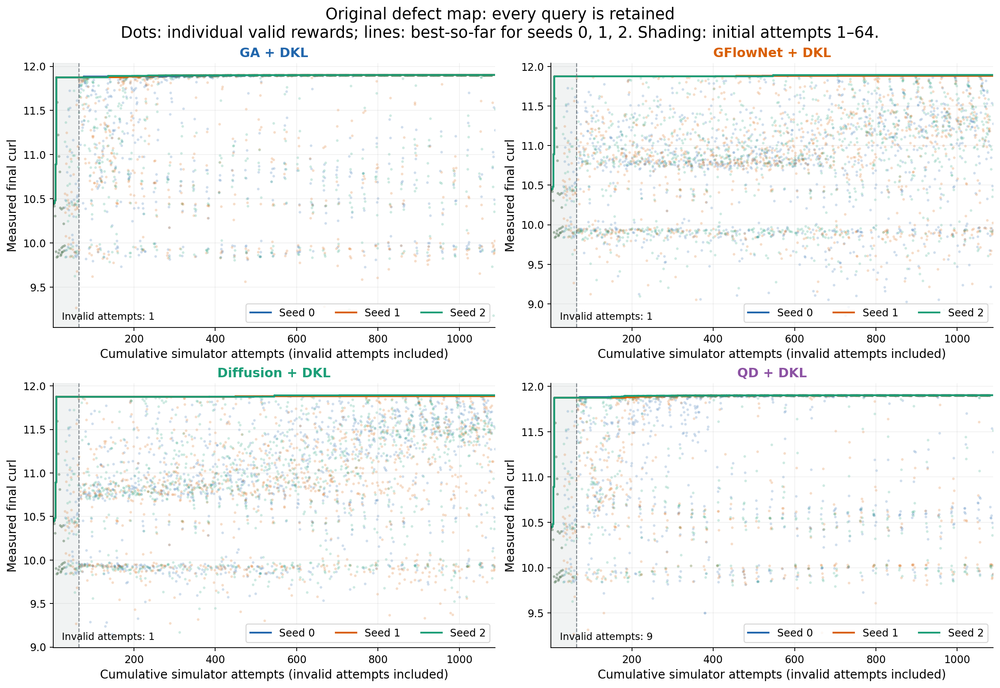

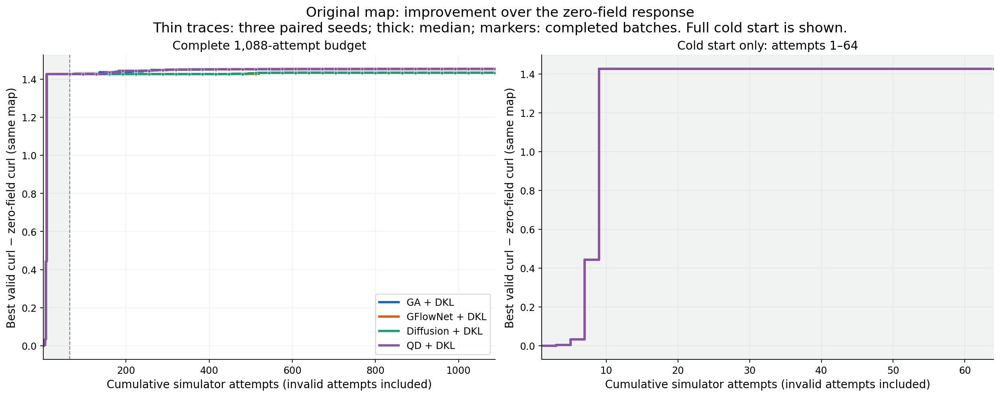

In [7]:
study_figure("baseline_individual_rewards")
study_figure("baseline_best_so_far")

### Every generation contributes to the empirical Pareto front

Complexity is minimized and measured final curl is maximized. The retained
front is cumulative: an early simple control remains eligible even after
later generations find a more complex champion. Black edges identify final
front points; their fills retain the generation color. The next plot exposes
small reward differences with a percentage-loss axis. Only that zoom omits
the zero-complexity control; the full front includes it.

These per-method fronts pool **three seeds**, so they are a descriptive
archive of 3 × 1,088 observations per method. They should not be read as the
outcome of a single 1,088-query trajectory.

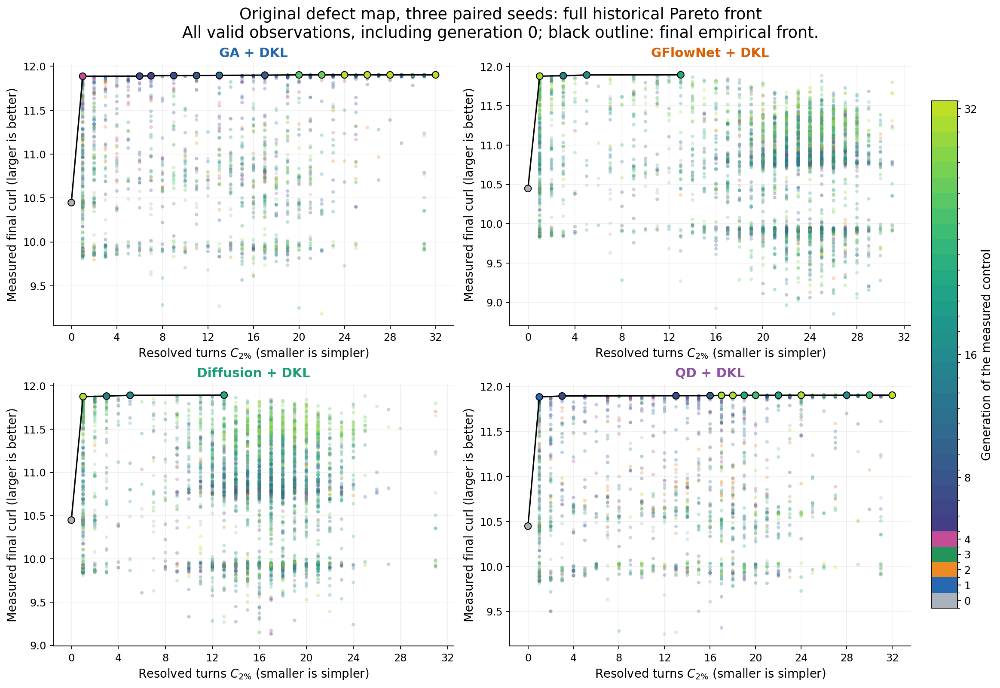

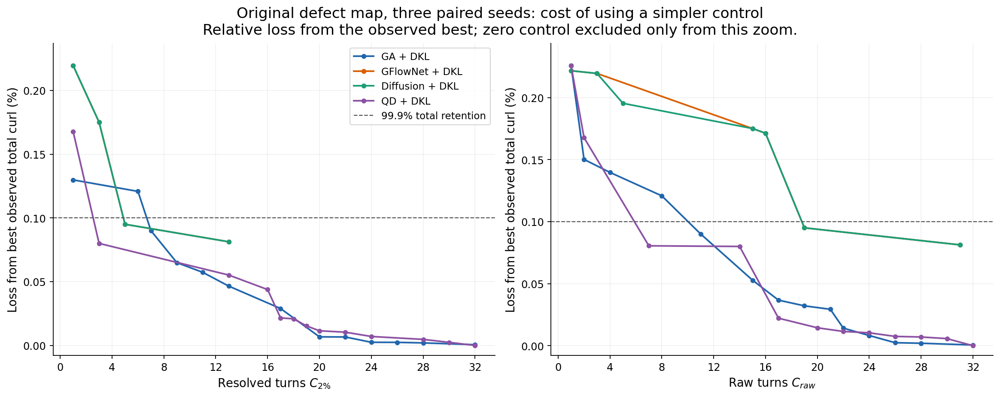

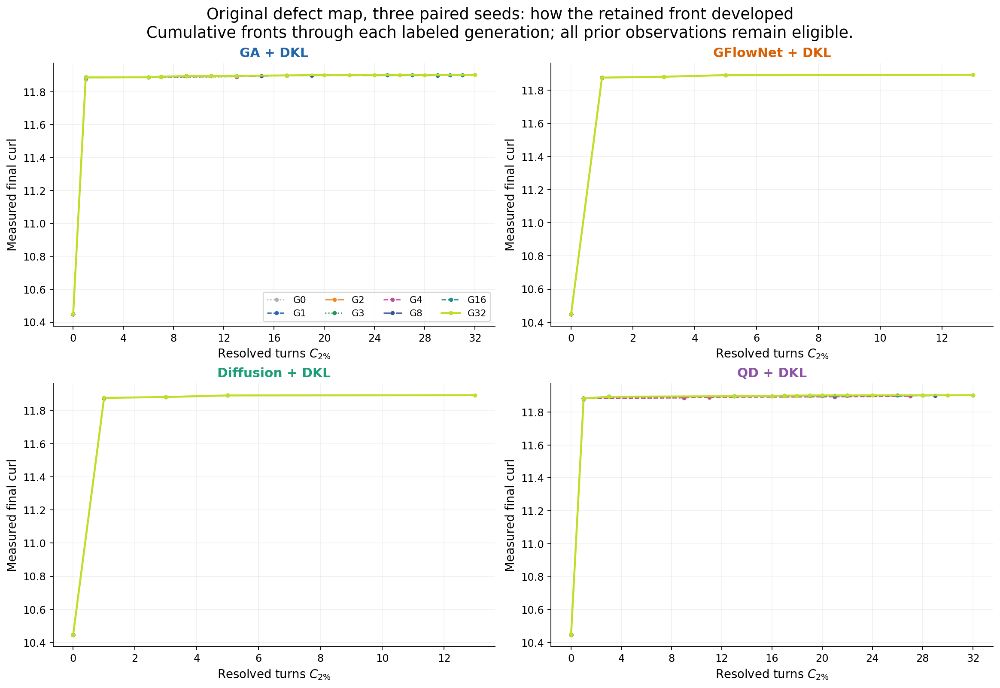

Full raw-turn and generation-history figures are exported in `figures/study/`; both complexity definitions are included in the CSV fronts.

In [8]:
study_figure("baseline_pareto_resolved")
study_figure("baseline_pareto_zoom")
study_figure("baseline_front_history_resolved")
if SHOW_SUPPLEMENTARY:
    study_figure("baseline_pareto_raw")
    study_figure("baseline_front_history_raw")
display(Markdown("Full raw-turn and generation-history figures are exported in `figures/study/`; both complexity definitions are included in the CSV fronts."))

### A champion versus a nearly optimal simple control

We report separate parsimony criteria:

\[
R\geq0.999R_{\max}
\qquad\text{and}\qquad
R\geq R_0+0.99(R_{\max}-R_0),
\]

where \(R_0\) is this map's zero-field reward and \(R_{\max}\) is its best
observed reward pooled over all four methods and three seeds. The second
threshold retains 99% of the *improvement* over zero field. A large baseline
can make 99.9% retention of total curl a different target. For each threshold
we select the lowest observed resolved complexity, break ties by reward and
then amplitude, and export the exact coefficients. The conjunction of the
two thresholds is an additional comparison, not a replacement for the two
separate definitions.

,selection,y,complexity,raw_turns,peak_ec,total_curl_retention,gain_retention,method,seed,generation,proposal_source
0,best_overall,11.902631,32,32,36.769793,1.000000,1.000000,qd_dkl,0,32,method_proposer
1,best_resolved_le1,11.887179,1,9,9.284822,0.998702,0.989378,ga_dkl,0,4,method_proposer
2,best_resolved_le3,11.893106,3,14,12.735670,0.999200,0.993452,qd_dkl,1,6,method_proposer
3,best_raw_le1,11.876246,1,1,8.006892,0.997783,0.981863,diffusion_dkl,2,11,common_prior
4,parsimonious_total_99_9,11.893106,3,14,12.735670,0.999200,0.993452,qd_dkl,1,6,method_proposer
5,parsimonious_gain_99,11.893106,3,14,12.735670,0.999200,0.993452,qd_dkl,1,6,method_proposer
6,parsimonious_raw_total_99_9,11.893047,5,7,13.603777,0.999195,0.993412,qd_dkl,1,9,method_proposer
7,parsimonious_raw_gain_99,11.893047,5,7,13.603777,0.999195,0.993412,qd_dkl,1,9,method_proposer
8,parsimonious_joint,11.893106,3,14,12.735670,0.999200,0.993452,qd_dkl,1,6,method_proposer
9,parsimonious_raw_joint,11.893047,5,7,13.603777,0.999195,0.993412,qd_dkl,1,9,method_proposer


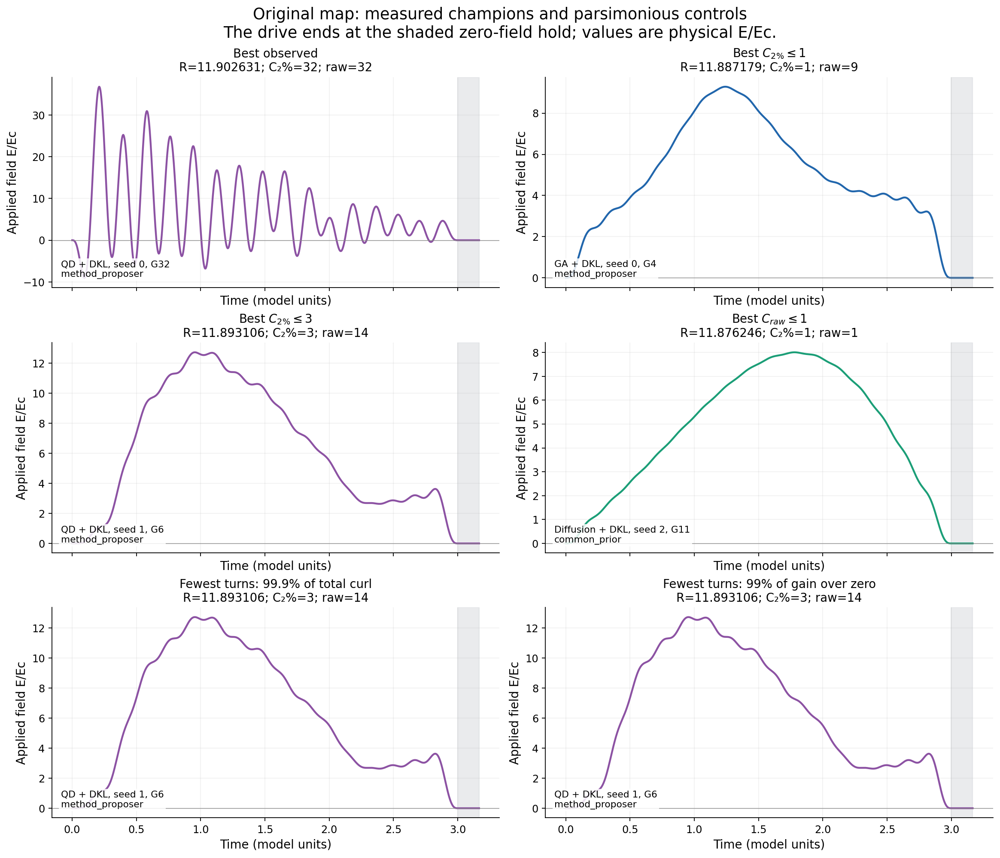

In [9]:
original_controls = selected.loc[selected.disorder == "baseline"]
display(original_controls[["selection", "y", "complexity", "raw_turns", "peak_ec",
                           "total_curl_retention", "gain_retention", "method", "seed",
                           "generation", "proposal_source"]])
study_figure("baseline_champion_simple_controls")

### Recompute the original report and Fourier spectra

The original detailed analysis remains executable. It adds source-specific
maxima, hypervolume relative to the zero-field response, complexity
sensitivity, later-generation improvement diagnostics, representative
Pareto controls, and the physical 34-amplitude spectra. These diagnostics
describe the completed finite budget; they do not certify a global maximum.

{
  "analysis_json": "/workspace/scratch/f9f14beb4ada/FerroNet_Optimization/curl/Fourier_descriptors/analysis/baseline_recomputed/analysis.json",
  "runs_available": 12,
  "missing_runs": [],
  "per_method_best_ranges": {
    "ga_dkl": {
      "count": 3,
      "minimum": 11.902244119894359,
      "median": 11.902395335981653,
      "maximum": 11.902563595783374
    },
    "gflownet_dkl": {
      "count": 3,
      "minimum": 11.881797117706519,
      "median": 11.882241086533064,
      "maximum": 11.892953400101176
    },
    "diffusion_dkl": {
      "count": 3,
      "minimum": 11.881797117706519,
      "median": 11.882241086533064,
      "maximum": 11.892953400101176
    },
    "qd_dkl": {
      "count": 3,
      "minimum": 11.902386681760976,
      "median": 11.902592146602814,
      "maximum": 11.902631153901796
    }
  },
  "pooled_champion": {
    "method": "qd_dkl",
    "seed": 0,
    "history_path": "qd_dkl/seed_0/history.npz",
    "row_index_zero_based": 1063,
    "iteration":

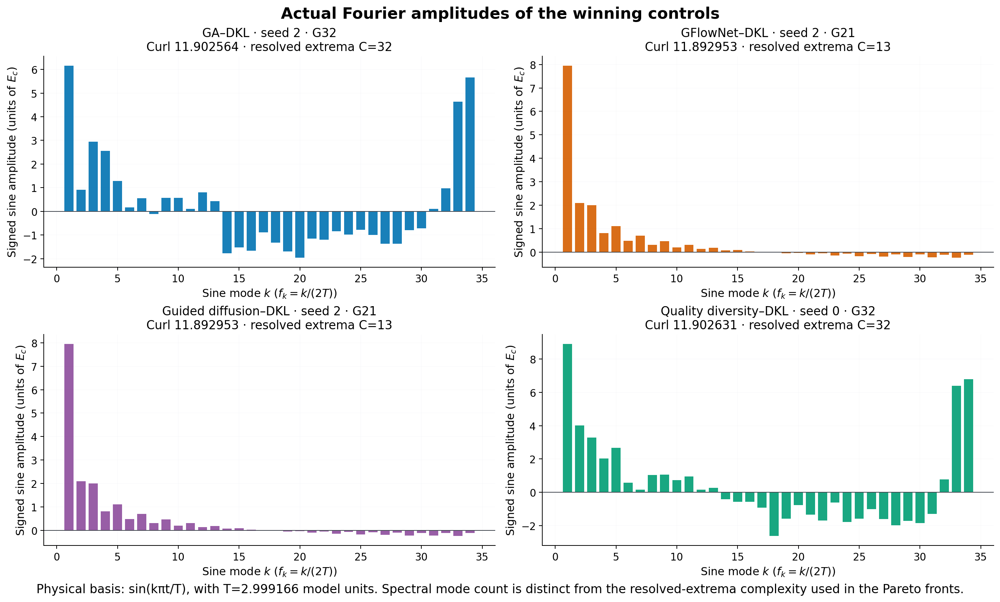

In [10]:
import analyze_results
import plots
baseline_report = analyze_results.main([
    "--results", str(ACTIVE_BASELINE),
    "--output", str(ROOT / "analysis/baseline_recomputed"),
    "--expected-seeds", "0,1,2",
])
baseline_plot_summary = plots.create_figures(ACTIVE_BASELINE, ROOT / "figures/baseline")
show_figure("figures/baseline/winner_fourier_spectra.png")
if SHOW_SUPPLEMENTARY:
    show_figure("figures/baseline/pareto_front_history.png")
    show_figure("figures/baseline/pareto_waveforms.png")

### Physics checks, spatial curl, and amplitude dependence

The selected controls were re-evaluated with refined time integration. The
archive includes the original zero response, winner time histories, final
polarization/curl fields, and a scalar amplitude sweep of the selected
waveform. The figures below are recomputed from those **archived validation
trajectories**, separately from optimization. Numerical refinement and
native guard checks are reported before interpreting small curl differences.

Removing an amplitude bound allows the search to discover its useful scale.
It does not assume that arbitrarily large fields improve curl. The sweep
measures that question for the chosen waveform, within the tested scale
factors; it is not a proof about every possible waveform.

{'all_fidelity2_valid': True,
 'all_fidelity2_within_native_guard': True,
 'all_complexity_grid_counts_match': True,
 'all_archived_complexity_counts_match': True,
 'all_archive_reward_refinements_pass': True,
 'all_winner_fidelity2_vs4_checks_pass': True,
 'max_abs_curl_change_from_archive': 1.6302514893595799e-10,
 'sweep_all_valid': True,
 'sweep_native_guard_exceeded_count': 0}

,method,method_label,seed,generation,full_curl,interior_curl,boundary_curl,zero_drive_full_curl,zero_drive_interior_curl,...,interior_gain_over_zero,boundary_gain_over_zero,interior_fraction_of_full_gain,full_trace_vs_map_abs_error,interior_trace_vs_map_abs_error,field_peak_ec,max_abs_P,status,native_guard_exceeded
0,ga_dkl,GA–DKL,2,32,11.902564,9.579852,2.322711,10.447896,8.216424,...,1.363428,0.091240,0.937278,0.000000,0.000000,30.209912,0.460340,0,False
1,gflownet_dkl,GFlowNet–DKL,2,21,11.892953,9.581453,2.311501,10.447896,8.216424,...,1.365028,0.080029,0.944619,0.000000,0.000000,8.681363,0.408623,0,False
2,diffusion_dkl,Guided diffusion–DKL,2,21,11.892953,9.581453,2.311501,10.447896,8.216424,...,1.365028,0.080029,0.944619,0.000000,0.000000,8.681363,0.408623,0,False
3,qd_dkl,Quality diversity–DKL,0,32,11.902631,9.579267,2.323365,10.447896,8.216424,...,1.362842,0.091893,0.936832,0.000000,0.000000,36.769459,0.520377,0,False


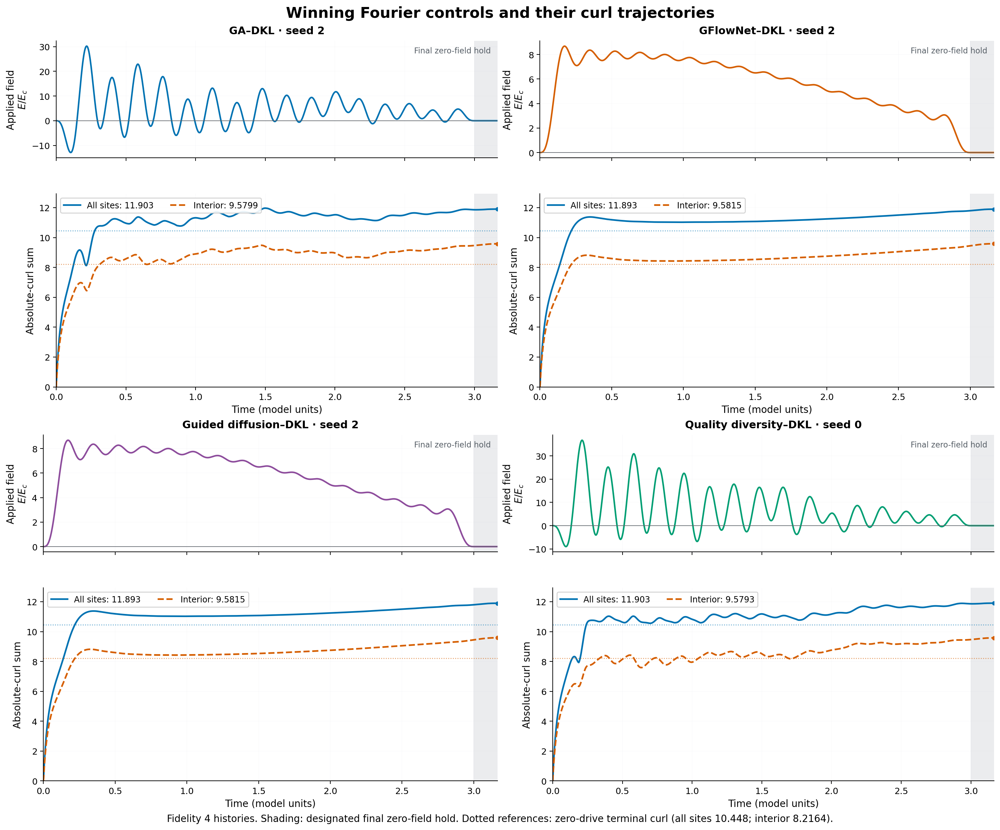

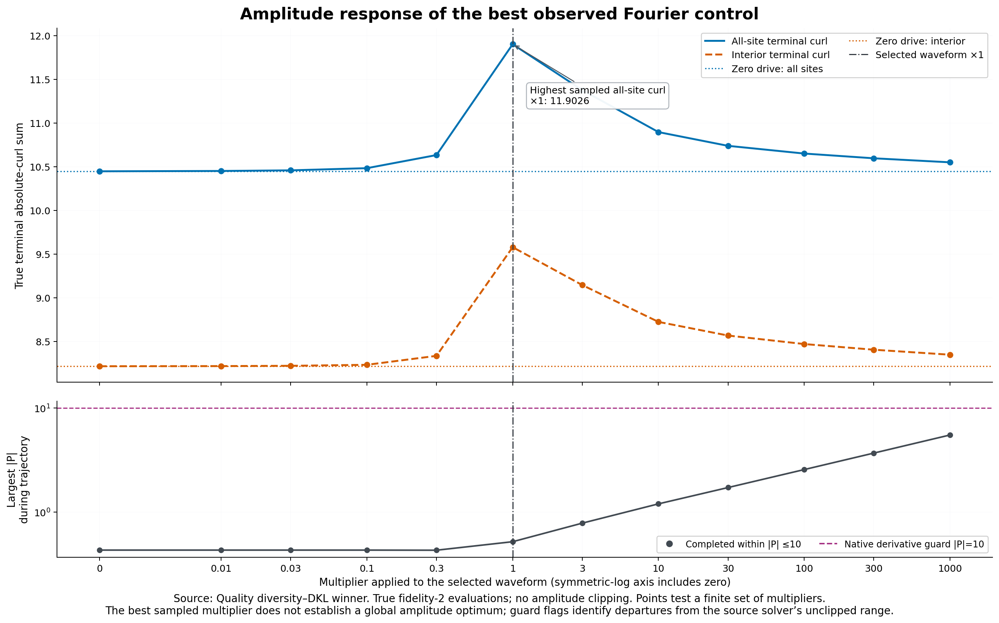

In [11]:
baseline_validation = json.loads((VALIDATION_ROOT / "baseline/finalist_validation.json").read_text())
if RUN_SIMULATIONS and not RUN_FULL_REVALIDATION:
    display(Markdown("This physics section validates the frozen release baseline controls. Freshly selected controls require their own refinement if they differ."))
display(baseline_validation["checks"])
import plot_physics
physics = plot_physics.create_physics_figures(VALIDATION_ROOT / "baseline", BASELINE_PHYSICS)
display(pd.DataFrame(physics["method_summaries"]))
show_figure(str((BASELINE_PHYSICS / "winner_physics_histories.png").relative_to(ROOT)))
show_figure(str((BASELINE_PHYSICS / "winner_amplitude_response.png").relative_to(ROOT)))
if SHOW_SUPPLEMENTARY:
    show_figure(str((BASELINE_PHYSICS / "winner_curl_spatial_maps.png").relative_to(ROOT)))

## 4. What changed when the original spline study became Fourier?

The same unoptimized initial template families were projected into the new
Fourier space and physically re-evaluated. No optimized spline winner was
inserted into the Fourier initialization. Projection does not preserve every
waveform exactly, and can introduce small oscillations that change either
raw or resolved complexity. We recompute the projection errors from the
stored source controls and compare all three seeds at the same query budget.

This is a descriptive comparison of two finite-budget searches. The two
waveform spaces, endpoint geometry, and induced priors differ. A score
difference or optimizer ranking therefore does not by itself establish
intrinsic superiority of a basis or search algorithm.

,seed,median_relative_L2_error,maximum_relative_L2_error,controls_with_changed_resolved_complexity
0,0,0.027186,0.314121,17
1,1,0.018740,0.182993,13
2,2,0.028864,0.169623,17


{'seed': 0,
 'count': 64,
 'oracle_fidelity': 1,
 'projection_matrix_rank': 32,
 'projection_matrix_condition': 8.558574617656241,
 'least_squares_normal_equation_relative_residual': 1.2958752993687304e-15,
 'projected_initial_matches_actual_initial_bitwise': True,
 'relative_waveform_L2_error_median': 0.027186041331959912,
 'relative_waveform_L2_error_max': 0.31412128466862643,
 'relative_peak_change_min': -0.0890633185631331,
 'relative_peak_change_max': 0.12748915862830468,
 'curl_change_min': -0.18481089499853276,
 'curl_change_max': 1.5387914656585604,
 'curl_change_abs_max': 1.5387914656585604,
 'curl_change_abs_median': 0.02025387849257143,
 'original_best_initial_curl': 11.878427377880804,
 'fourier_best_initial_curl': 11.874983685263242,
 'fourier_all_numerically_valid': True,
 'fourier_native_guard_crossings': 0,
 'fourier_complexity_grid_mismatches': 0,
 'fourier_complexity_derivative_root_mismatches': 0,
 'controls_with_changed_complexity_after_projection': 17,
 'original_C

,representation,representation_label,method,method_label,seeds,budget_per_seed,best_curl_across_seeds,median_seed_best_curl,min_seed_best_curl,...,median_initial_best_curl,median_gain_over_own_initial,winner_seed,winner_evaluation_number,winner_generation,winner_complexity,winner_peak_field_Ec,winner_proposal_source,winner_selection_source
0,spline,Spline,ga_dkl,GA–DKL,3,1088,11.906136,11.903157,11.902689,...,11.878427,0.024729,0,1076,32,13,42.483465,method_proposer,dkl_ucb
1,spline,Spline,gflownet_dkl,GFlowNet–DKL,3,1088,11.898480,11.893784,11.890164,...,11.878427,0.015357,2,705,21,1,7.945214,common_prior,dkl_ucb
2,spline,Spline,diffusion_dkl,Guided diffusion–DKL,3,1088,11.898480,11.893784,11.890164,...,11.878427,0.015357,2,707,21,1,7.945214,common_prior,dkl_ucb
3,spline,Spline,qd_dkl,Quality diversity–DKL,3,1088,11.905001,11.904050,11.903408,...,11.878427,0.025623,1,1061,32,17,21.532453,method_proposer,dkl_ucb
4,fourier,Fourier,ga_dkl,GA–DKL,3,1088,11.902564,11.902395,11.902244,...,11.874984,0.027412,2,1059,32,32,30.229078,method_proposer,dkl_ucb
5,fourier,Fourier,gflownet_dkl,GFlowNet–DKL,3,1088,11.892953,11.882241,11.881797,...,11.874984,0.007257,2,705,21,13,8.682494,common_prior,dkl_ucb
6,fourier,Fourier,diffusion_dkl,Guided diffusion–DKL,3,1088,11.892953,11.882241,11.881797,...,11.874984,0.007257,2,705,21,13,8.682494,common_prior,dkl_ucb
7,fourier,Fourier,qd_dkl,Quality diversity–DKL,3,1088,11.902631,11.902592,11.902387,...,11.874984,0.027608,0,1064,32,32,36.769793,method_proposer,dkl_ucb


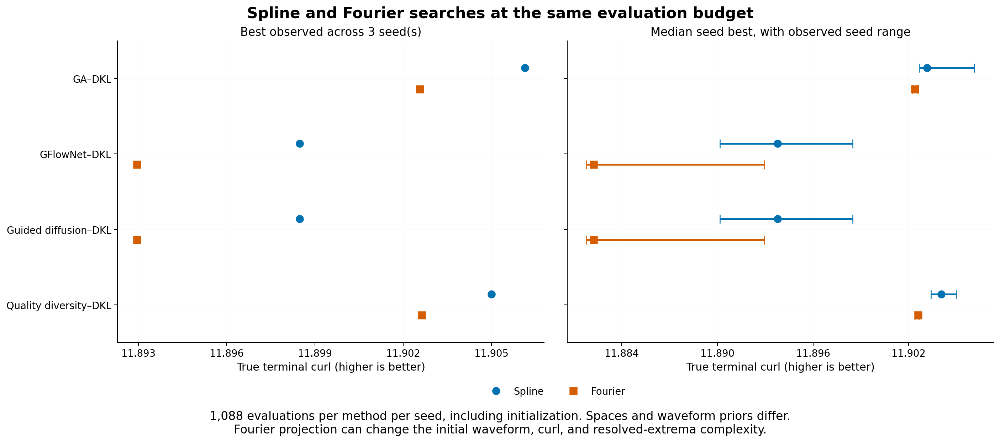

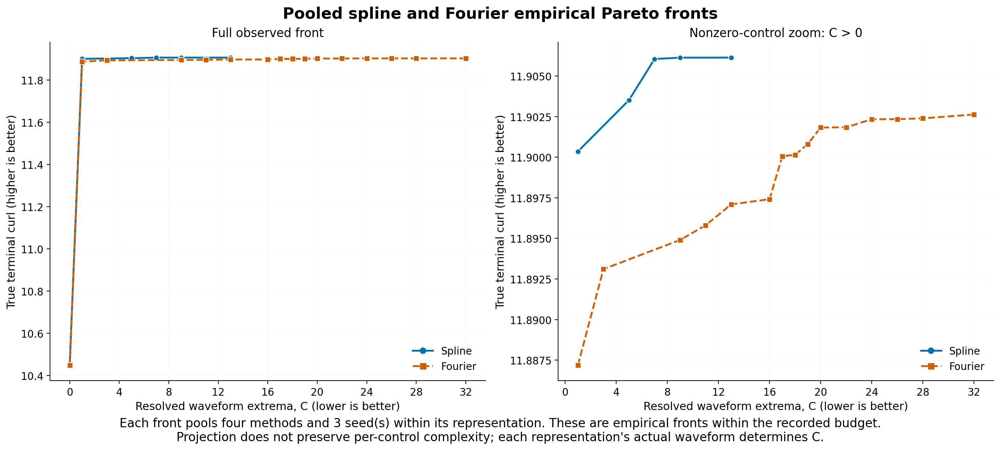

In [12]:
projection_rows = []
for seed in sa.SEEDS:
    initial_path = next((ROOT / "data/spline_reference/initial_reference").glob(f"seed_{seed}_*.npz"))
    with np.load(initial_path, allow_pickle=False) as archive:
        original_x = archive["x"].copy()
        source_C = archive["complexity"].copy()
    fourier_x = rep.project_spline_coordinates(original_x)
    with np.load(ACTIVE_BASELINE / f"ga_dkl/seed_{seed}/history.npz", allow_pickle=False) as archive:
        assert np.allclose(fourier_x, archive["x"][:64], rtol=1e-12, atol=1e-12)
    source_waves = rep.spline_reference.fields(original_x, n=4097)
    projected_waves = rep.fields(fourier_x, n=4097)
    denominator = np.linalg.norm(source_waves, axis=1)
    error = np.divide(np.linalg.norm(projected_waves - source_waves, axis=1), denominator,
                      out=np.zeros(len(denominator)), where=denominator > 0)
    projected_C = rep.complexity(fourier_x)["turns"]
    projection_rows.append({"seed": seed, "median_relative_L2_error": np.median(error),
                            "maximum_relative_L2_error": np.max(error),
                            "controls_with_changed_resolved_complexity": int(np.count_nonzero(source_C != projected_C))})
display(pd.DataFrame(projection_rows))
projection_validation = read_json("validation/representation/representation_validation.json")
display(projection_validation["initial_projection_summary"])

import compare_representations
comparison = compare_representations.compare_representations(
    ROOT / "data/spline_reference", ACTIVE_BASELINE,
    ROOT / "figures/spline_comparison", budget=1088, seeds=(0, 1, 2))
display(pd.read_csv(ROOT / "figures/spline_comparison/comparison_methods.csv"))
show_figure("figures/spline_comparison/comparison_method_scores.png")
show_figure("figures/spline_comparison/comparison_pareto_pooled.png")
if SHOW_SUPPLEMENTARY:
    show_figure("figures/spline_comparison/comparison_convergence.png")
    show_figure("figures/spline_comparison/comparison_winner_waveforms.png")

### Post-search transfer of two optimized spline controls

A separate diagnostic projects the earlier spline champion and its simplest
99.9%-retaining control into Fourier space. These two optimized controls were
evaluated **after** searching and were never added to Fourier initialization,
surrogate training, or proposal pools. They test how much of those particular
shapes and scores survives projection; they do not alter the budget-matched
comparison. The table includes both score loss and any added extrema from
ringing. The two physical evaluations have their own ledger.

To repeat this diagnostic with new simulator calls, run
`python posthoc_spline_transfer.py --help` and choose a separate output
directory. Default notebook replay reads the frozen diagnostic.

In [13]:
display(pd.read_csv(ROOT / "validation/spline_transfer/transfer_summary.csv"))
display(read_json("validation/spline_transfer/evaluation_ledger.json"))
if SHOW_SUPPLEMENTARY:
    show_figure("validation/spline_transfer/transfer_waveform_comparison.png")

,diagnostic,source_candidate_id,original_complexity,fourier_complexity,original_raw_turns,fourier_raw_turns,original_turns_1pct,fourier_turns_1pct,original_turns_5pct,...,curl_change,original_interior_fidelity2,fourier_interior_fidelity2,interior_change,fourier_valid,native_guard_exceeded,max_abs_P,status,excluded_from_initialization_training_and_budget
0,prior_global_champion,candidate_0005,13,13,19,19,13,15,9,...,-0.022169,9.577377,9.561680,-0.015698,True,False,0.607694,0,True
1,prior_simplest_99_9percent,candidate_0001,1,21,1,31,1,31,1,...,-0.006608,9.582539,9.578454,-0.004085,True,False,0.409290,0,True


{'new_true_waveform_evaluations': 2,
 'oracle_batch_calls': 2,
 'source_rewards_recomputed': False,
 'cached_source_rewards_fidelity': 2,
 'projected_rewards_fidelity': 2,
 'optimizer_evaluations_added': 0,
 'optimizer_histories_modified': False,
 'purpose': 'Two post hoc projections of prior spline controls on the original fixed defect map'}

## 5. Ten new defect maps: geometry and controls fixed before searching

Each new map has 19 occupied sites sampled without replacement from the
20 × 20 grid. The original 19 defect vectors are preserved and assigned to
those locations. The manifest records the master seed, child seed sequence,
exact sites, vectors, file hashes, and numeric hashes. These maps are a
reproducible finite sample of placements, not an exhaustive disorder ensemble.
The ten maps are independent placement draws. The three optimizer seeds are
repeated searches on each fixed map, giving a separate source of variation.

Zero-field and fixed-pulse responses already differ across maps. We therefore
show both absolute curl and improvement over each map's own zero-field
response. Structural descriptors and the placement summary are exported;
ten maps support descriptive comparisons, not a high-dimensional causal
regression of defect geometry.

{'all_maps_preserve_exact19_defect_vectors': True,
 'all_file_and_numeric_hashes_match': True,
 'fixed_explicit_map_matches_default_bitwise': True,
 'fixed_zero_curl': 10.447895713354447,
 'ABA': {'map_A': 'd00',
  'map_B': 'd01',
  'reward_A_equals_Arepeat_bitwise': True,
  'state_A_equals_Arepeat_bitwise': True,
  'A_reward': [10.193674849445328, 11.658524275234784],
  'B_reward': [8.984946805945366, 10.892414872814882],
  'max_abs_state_difference_A_B': 0.35299279062756783},
 'all_baseline_and_probe_evaluations_valid': True,
 'oracle_source_unchanged': True,
 'oracle_file_sha256': '81093544a4256bcdc8d303ccc86ee15ac99b9e787326554c4df6fd02f5b28020',
 'explicit_map_interface': 'evaluate_fields(fields_ec, defects_ec=array_float64_20x20x2)',
 'no_global_defect_mutation_used': True,
 'diagnostic_evaluation_budget': {'random_maps_zero_and_fixed_probe': 20,
  'original_fixed_map_zero_and_fixed_probe': 2,
  'ABA_check': 6,
  'default_map_exact_agreement': 2,
  'total_true_waveform_evaluation

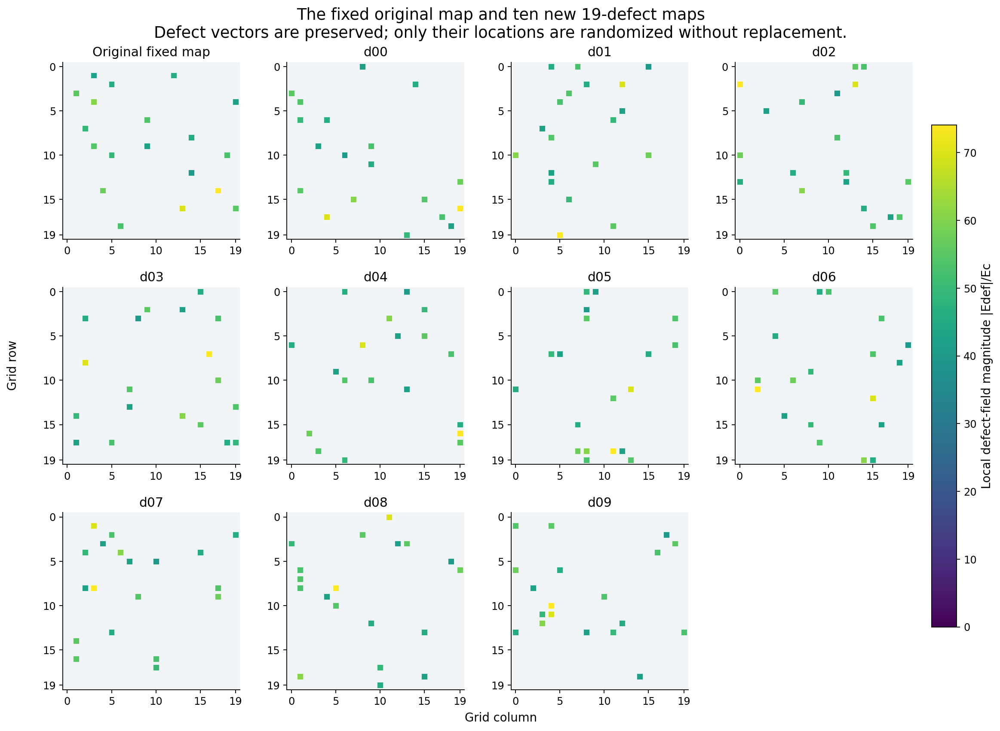

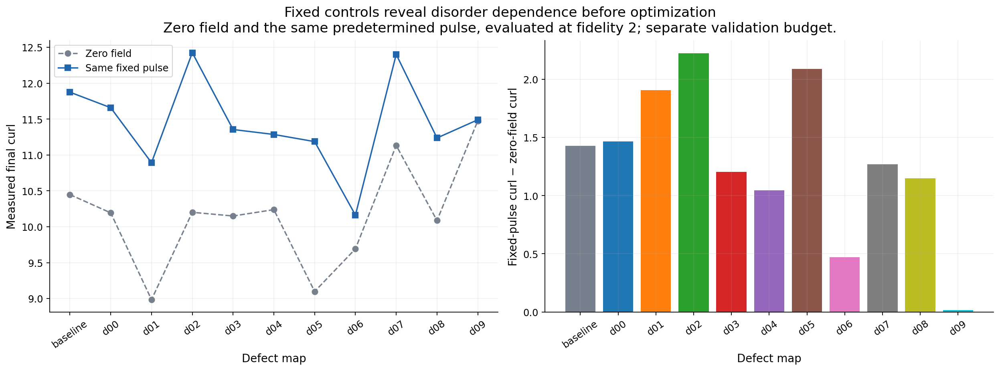

,disorder,zero_curl_f2,fixed_pulse_curl_f2,fixed_pulse_gain_f2,zero_valid,fixed_pulse_valid
0,baseline,10.447896,11.874984,1.427088,True,True
1,d00,10.193675,11.658524,1.464849,True,True
2,d01,8.984947,10.892415,1.907468,True,True
3,d02,10.201529,12.424989,2.223460,True,True
4,d03,10.150146,11.354898,1.204753,True,True
5,d04,10.238444,11.285890,1.047446,True,True
6,d05,9.098555,11.186358,2.087803,True,True
7,d06,9.692190,10.162948,0.470758,True,True
8,d07,11.132673,12.400956,1.268283,True,True
9,d08,10.086745,11.237091,1.150346,True,True


In [14]:
disorder_validation = read_json("data/disorders/numerical_validation.json")
display(disorder_validation)
study_figure("disorder_maps")
study_figure("fixed_control_baselines")
display(study_table("fixed_baselines_fidelity2"))

## 6. Full search trajectories across disorder and optimizer seeds

The individual-reward plot includes every generation and every seed. Each
map's three optimizer seeds share its paired initialization across methods.
Thin convergence traces summarize maps, while the thick trace and band show
the median and middle half of map-level medians. These bands describe
**between-map variation**; they are not confidence intervals and do not stand
in for variability of the three seeds on a fixed map.

The normalized figure divides each run's best gain above zero by the best
gain observed across all four methods and three seeds on that same map.
It shows the full range, then a clearly labeled adaptive-stage zoom from
95% to 100% retention. The denominator is fixed after the study and is an
empirical comparison reference, not a known true optimum or information
supplied to the optimizer. The original absolute-gain view remains above it.
Completed-batch markers preserve the distinction between archived query
ordering and actual adaptive decisions. The 95%/99% target table uses the
post-hoc pooled best gain on the same map as its reference and reports the
first **completed batch cost**, with non-reaching runs explicitly marked.

,disorder,method,median_best_curl,min_best_curl,best_curl,median_gain_over_zero,seed_std_curl
4,d00,diffusion_dkl,11.895016,11.868681,11.943870,1.701342,0.038152
5,d00,ga_dkl,11.975525,11.973879,11.976105,1.781850,0.001155
6,d00,gflownet_dkl,11.895016,11.853618,11.943870,1.701342,0.045177
7,d00,qd_dkl,11.974341,11.965422,11.975471,1.780666,0.005505
8,d01,diffusion_dkl,11.102758,11.016852,11.153680,2.117812,0.069155
9,d01,ga_dkl,11.212579,11.026862,11.300988,2.227632,0.139912
10,d01,gflownet_dkl,11.004923,11.004026,11.102758,2.019976,0.056746
11,d01,qd_dkl,11.177411,11.026335,11.182610,2.192464,0.088762
12,d02,diffusion_dkl,12.541823,12.533600,12.543861,2.340295,0.005432
13,d02,ga_dkl,12.558104,12.555169,12.558993,2.356575,0.002001


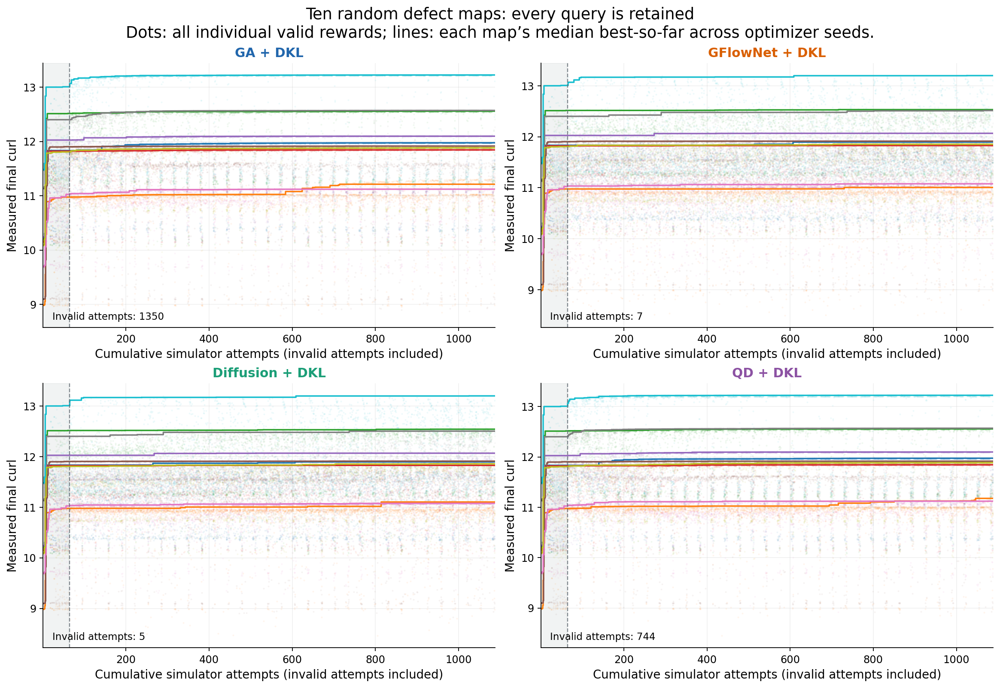

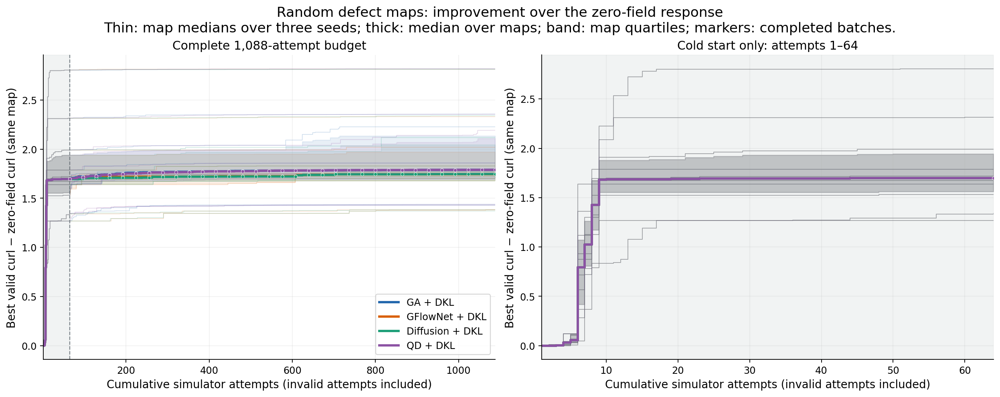

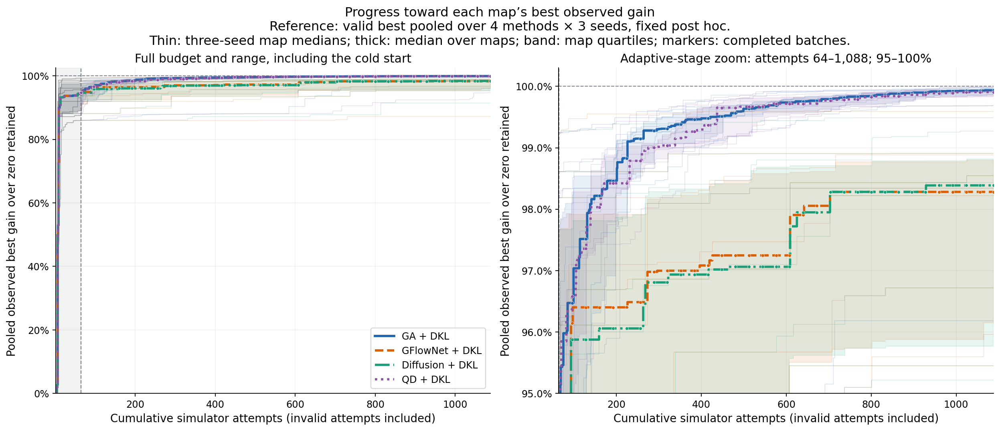

,method,target_gain_fraction,reached,runs,not_reached,median_completed_batch_cost_among_reached,min_completed_batch_cost_among_reached,max_completed_batch_cost_among_reached
8,diffusion_dkl,0.950000,25,30,5,64.000000,64.000000,768.000000
9,diffusion_dkl,0.990000,8,30,22,368.000000,64.000000,1056.000000
10,ga_dkl,0.950000,29,30,1,64.000000,64.000000,704.000000
11,ga_dkl,0.990000,28,30,2,256.000000,64.000000,896.000000
12,gflownet_dkl,0.950000,25,30,5,64.000000,64.000000,768.000000
13,gflownet_dkl,0.990000,7,30,23,192.000000,64.000000,1056.000000
14,qd_dkl,0.950000,27,30,3,64.000000,64.000000,224.000000
15,qd_dkl,0.990000,26,30,4,288.000000,64.000000,768.000000


The median hitting cost is conditional on reaching the target; the reached/run columns must be read with it. The exported `query_target_summary.csv` accompanies full censored per-run results in `query_to_target.csv`.

In [15]:
ensemble_methods = method_summary.loc[method_summary.kind == "ensemble"]
display(ensemble_methods[["disorder", "method", "median_best_curl", "min_best_curl",
                          "best_curl", "median_gain_over_zero", "seed_std_curl"]])
study_figure("ensemble_individual_rewards")
study_figure("ensemble_best_so_far")
study_figure("ensemble_gain_retention_progress")
target_summary = study_table("query_target_summary")
display(target_summary.loc[target_summary.kind == "ensemble", [
    "method", "target_gain_fraction", "reached", "runs", "not_reached",
    "median_completed_batch_cost_among_reached", "min_completed_batch_cost_among_reached",
    "max_completed_batch_cost_among_reached"]])
display(Markdown("The median hitting cost is conditional on reaching the target; the reached/run columns must be read with it. The exported `query_target_summary.csv` accompanies full censored per-run results in `query_to_target.csv`."))

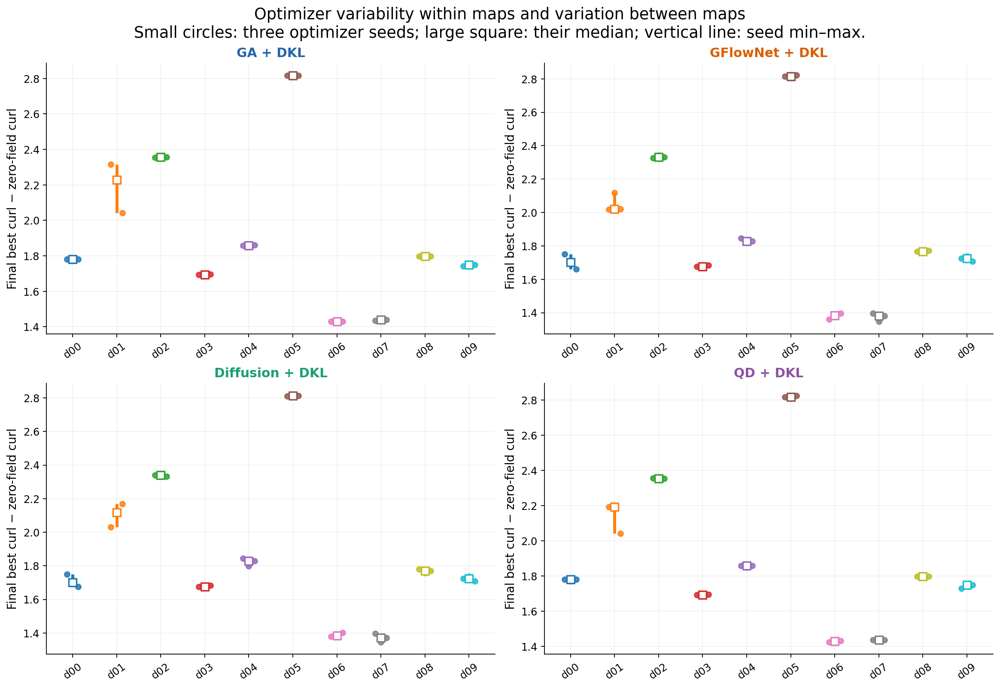

,method,disorders,between_disorder_variance_of_seed_means,mean_within_disorder_seed_variance,meaning
0,diffusion_dkl,10,0.193292,0.000795,"Descriptive sample variances; three optimizer seeds per map,..."
1,ga_dkl,10,0.184684,0.001960,"Descriptive sample variances; three optimizer seeds per map,..."
2,gflownet_dkl,10,0.191903,0.000667,"Descriptive sample variances; three optimizer seeds per map,..."
3,qd_dkl,10,0.182633,0.000810,"Descriptive sample variances; three optimizer seeds per map,..."


,median_G24_to_G32_gain,largest_G24_to_G32_gain,median_fraction_of_total_gain_in_last8
method,,,
diffusion_dkl,0.000000,0.019672,0.000000
ga_dkl,0.000616,0.030939,0.000313
gflownet_dkl,0.000000,0.022853,0.000000
qd_dkl,0.000938,0.071475,0.000450


The complete per-run G24-to-G32 improvements and their fractions of total gain are in `run_summary.csv`. Continued improvement and flat late curves describe this fixed budget; neither certifies convergence or a global maximum.

In [16]:
study_figure("ensemble_seed_vs_disorder_variation")
display(study_table("variance_components"))
late_improvement = run_summary.loc[run_summary.kind == "ensemble", [
    "disorder", "method", "seed", "best_through_generation24", "best_y",
    "last8_generation_curl_improvement", "last8_improvement_fraction_of_total_gain"]]
display(late_improvement.groupby("method").agg(
    median_G24_to_G32_gain=("last8_generation_curl_improvement", "median"),
    largest_G24_to_G32_gain=("last8_generation_curl_improvement", "max"),
    median_fraction_of_total_gain_in_last8=("last8_improvement_fraction_of_total_gain", "median")))
display(Markdown("The complete per-run G24-to-G32 improvements and their fractions of total gain are in `run_summary.csv`. Continued improvement and flat late curves describe this fixed budget; neither certifies convergence or a global maximum."))

## 7. Historical Pareto fronts and the value of simplicity

Each map's front pools the full history of **four methods × three seeds ×
1,088 observations**. Shared cold-start rows are present in each method's
archive; duplicate rows do not change dominance. This pooled front is an
archive of alternatives, with a larger total search effort than a single
convergence curve. Every generation remains eligible.

Raw extrema and resolved 2% extrema are both exported. The threshold panels
compare the best measured unrestricted control, the best with at most one
resolved turn, the best with at most three resolved turns, and the best with
at most one raw turn. The two retention definitions are then evaluated
separately, including cases where the simpler total-curl threshold retains
noticeably less of the gain above zero.

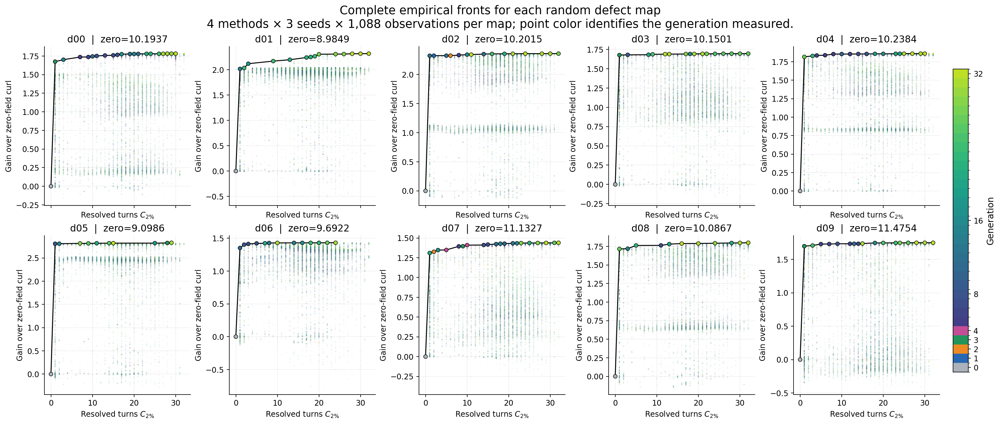

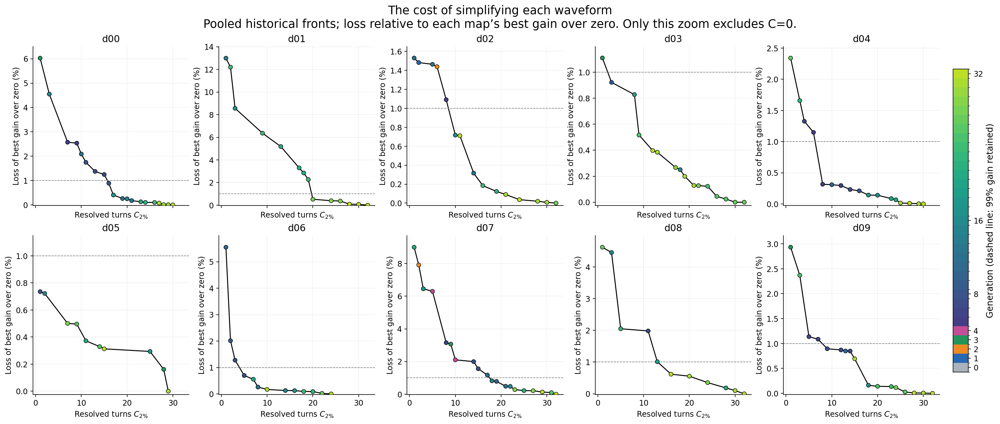

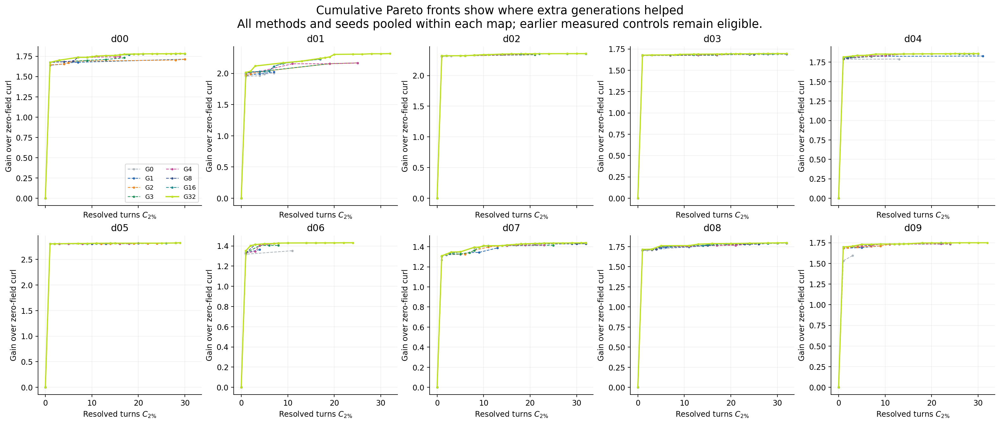

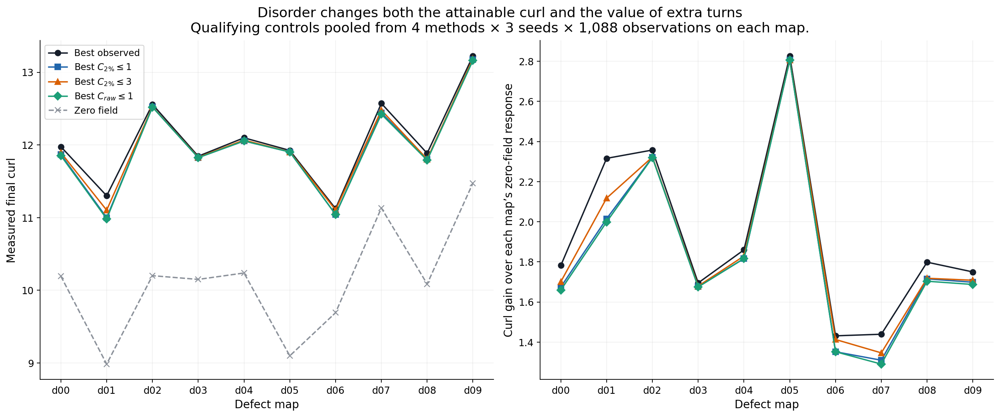

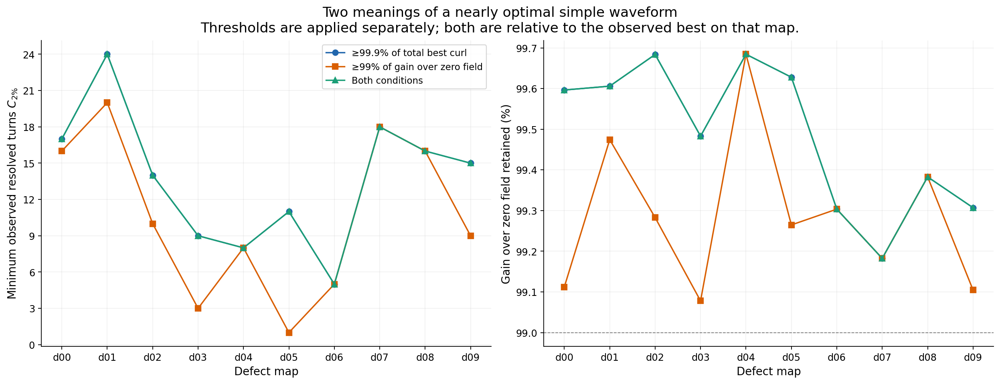

,disorder,selection,y,complexity,raw_turns,gain_retention,peak_ec
10,d00,best_overall,11.976105,30,32,1.000000,9.954448
11,d00,best_resolved_le1,11.868681,1,3,0.939732,2.774382
12,d00,best_resolved_le3,11.895016,3,9,0.954507,2.589580
13,d00,best_raw_le1,11.853618,1,1,0.931281,2.978905
14,d00,parsimonious_total_99_9,11.968910,17,19,0.995963,7.833861
15,d00,parsimonious_gain_99,11.960280,16,22,0.991122,4.658338
20,d01,best_overall,11.300988,32,32,1.000000,44.680249
21,d01,best_resolved_le1,11.000167,1,7,0.870114,65978.708700
22,d01,best_resolved_le3,11.102758,3,7,0.914410,11.997845
23,d01,best_raw_le1,10.983969,1,1,0.863121,21257.018872


In [17]:
study_figure("ensemble_all_history_pareto_resolved")
study_figure("ensemble_pareto_zoom_resolved")
study_figure("ensemble_front_history_resolved")
study_figure("ensemble_complexity_tradeoff")
study_figure("ensemble_parsimony_thresholds")
if SHOW_SUPPLEMENTARY:
    study_figure("ensemble_all_history_pareto_raw")
    study_figure("ensemble_pareto_zoom_raw")
    study_figure("ensemble_front_history_raw")
display(selected.loc[(selected.disorder != "baseline") & selected.selection.isin([
    "best_overall", "best_resolved_le1", "best_resolved_le3", "best_raw_le1",
    "parsimonious_total_99_9", "parsimonious_gain_99"]), [
    "disorder", "selection", "y", "complexity", "raw_turns", "gain_retention", "peak_ec"]])

## 8. The actual waveforms, spectra, and source of the winners

The first comparison overlays each selected waveform divided by its own
dense-grid peak, with the actual peak and RMS printed beside it. These are
explicitly **shape comparisons**. Separate physical-amplitude panels then
show every map on its own linear y-axis. This preserves extreme fields
without letting one map flatten the other curves out of view. Alternatives
with at most one or three extrema above the 2% prominence threshold are both
included: this turn count does not
measure the field magnitude or its associated cost. Peak and RMS values use
the 4,097-point driven interval; the final zero-field hold is excluded from
those amplitude statistics.

The coefficient export includes both the 32 normalized free coordinates and the
34 actual sine amplitudes in units of Ec. Spectral energy fractions use
squared physical amplitudes; the spectral centroid is measured in cycles per
driven interval. Peak field, RMS field, resolved/raw complexity, and reward
remain available in the control and observation tables.

Different waveform shapes are evidence of different selected controls. The
transfer experiment in the next section tests whether those differences
have useful map-specific consequences.

Exported 110 control selections with exact coefficients and physical waveforms.


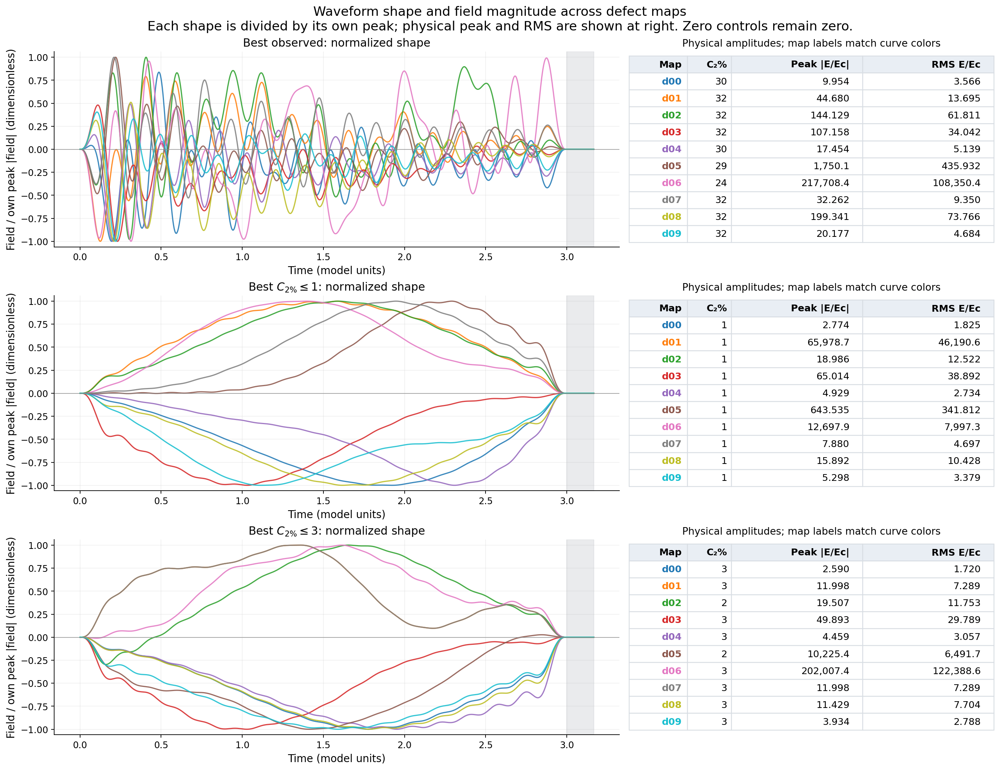

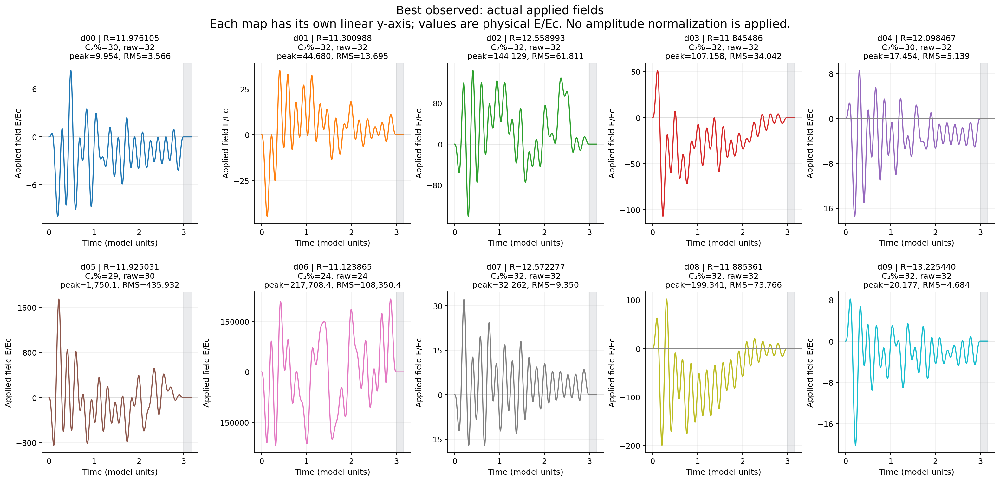

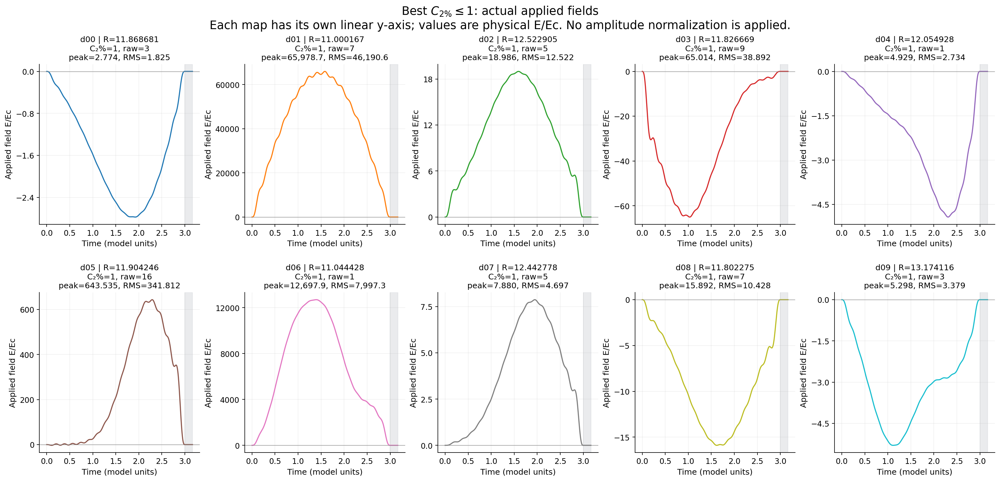

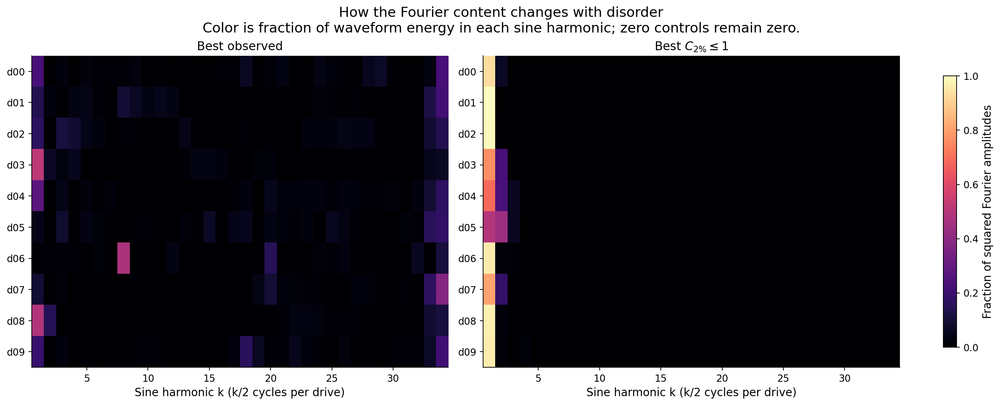

In [18]:
study_figure("ensemble_selected_waveforms")
study_figure("ensemble_unrestricted_physical_waveforms")
study_figure("ensemble_c1_physical_waveforms")
study_figure("ensemble_fourier_energy")
if SHOW_SUPPLEMENTARY:
    study_figure("ensemble_c3_physical_waveforms")
    study_figure("ensemble_retention_waveforms")
    study_figure("ensemble_waveform_properties")
controls = json.loads((TABLES / "selected_controls.json").read_text())
print(f"Exported {len(controls)} control selections with exact coefficients and physical waveforms.")

### Pipeline performance and proposer attribution

All pipelines can select candidates from a shared common prior. A winner in
a GFlowNet or diffusion run can therefore originate from that common pool.
The figure reports the actual `proposal_source` of each run's best result,
and names the source of each map's pooled champion. These data support
pipeline comparisons; they do not isolate the causal contribution of each
proposer without an ablation that changes only that component.

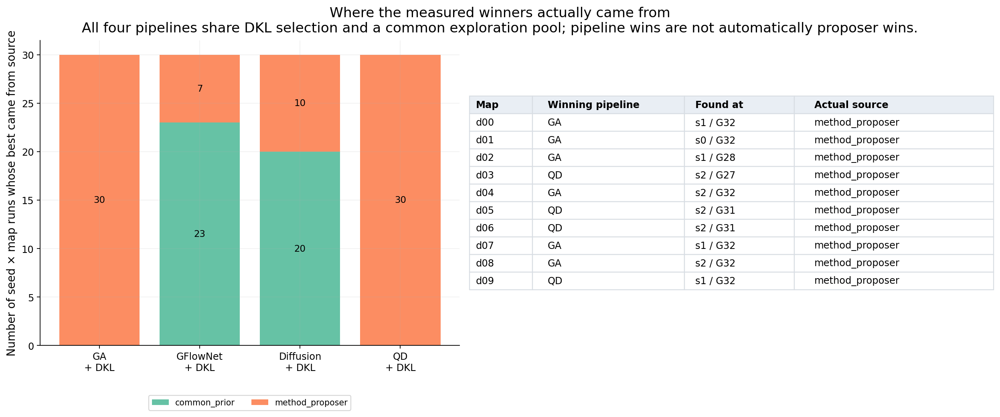

best_proposal_source,common_prior,method_proposer
method,,
diffusion_dkl,20,10
ga_dkl,0,30
gflownet_dkl,23,7
qd_dkl,0,30


In [19]:
study_figure("ensemble_winner_provenance")
source_counts = run_summary.loc[run_summary.kind == "ensemble"].groupby(
    ["method", "best_proposal_source"]).size().unstack(fill_value=0)
display(source_counts)

## 9. Independent numerical refinement and cross-map transfer

Selected unrestricted and parsimonious controls are re-evaluated with finer
integration and independent stationary-root complexity counts. Validation
queries are outside every optimizer's 1,088-attempt budget. The transfer
matrix evaluates each map's selected unrestricted and one-resolved-turn
controls on all ten target maps.

A heatmap entry is the target-map gain above its zero-field response,
divided by the gain of that target map's archived champion after the same
fidelity-2 refinement. Both numerator and denominator use fidelity 2.
Negative gains remain negative. Invalid results or a nonpositive reference
gain are marked missing. Values above 100% can occur because the reference
champion is a finite-search observation. The diagonal denotes the control's
source map; an off-diagonal winner can reveal useful transfer or a remaining
search gap.

A separate spatial accounting table splits each refined champion's gain
over zero field between the outermost 76 grid cells and the other 324 cells.
It uses the already computed fidelity-2 states and makes no extra simulator
queries. The perimeter share can be negative or exceed 100% when the two
regions change in opposite directions. This is an accounting identity on
the periodic grid, not a causal explanation or evidence for a physical edge.

{'checks': {'all_representative_refinements_pass': True,
  'all_representative_interior_refinements_pass': True,
  'all_extrema_checks_pass': True,
  'all_archive_extrema_checks_pass': True,
  'all_winner_fidelity2_vs4_pass': True,
  'all_winner_interior_fidelity2_vs4_pass': True,
  'all_representatives_valid': True,
  'max_archive_curl_refinement_change': 7.362582543635199e-08,
  'max_archive_interior_refinement_change': 1.106386093852052e-08,
  'transfer_invalid_pairs': 0,
  'transfer_pairs_exceeding_target_winner': 0}}

{'representative_controls': 69,
 'winner_fidelity4_controls': 10,
 'maximum_winner_full_curl_fidelity2_vs4_abs_change': 6.197232949034515e-09,
 'all_champions_increase_interior_curl': True}

,map,role,C2pct,raw_turns,peak_Ec_8193_point_grid,peak_Ec_900_simulator_samples,refinement_fidelity,max_abs_P,native_guard_exceeded,valid
0,d01,best_resolved_le1,1,7,65978.708700,65978.385010,2,6.708637,False,True
1,d06,global_best,24,24,217714.683021,217657.837732,4,9.984152,False,True
2,d06,best_resolved_le1,1,1,12697.872882,12697.835886,2,3.876677,False,True


The amplitude audit uses an independent 8,193-point grid and the actual 900 simulator samples; the main archive's amplitude statistics use 4,097 points. These can give slightly different peak estimates. A selected control can pass refinement while lying close to the existing native |P|=10 guard; turn count alone does not measure field cost or margin to that guard.

,map_id,candidate_id,roles,method,seed,row_index,generation,resolved_turns,raw_turns,...,full_gain_over_zero_f2,interior_gain_over_zero_f2,retained_total_reward_fraction_f2,retained_gain_fraction_f2,all_extrema_checks_pass,all_archive_count_checks_pass,valid,status,native_guard_exceeded
0,d00,d00_c000,zero_baseline,diffusion_dkl,0,0,0,0,0,...,0.000000,0.000000,0.851168,0.000000,True,True,True,0,False
1,d00,d00_c001,global_best,ga_dkl,1,1068,32,30,32,...,1.782430,1.372381,1.000000,1.000000,True,True,True,0,False
2,d00,d00_c002,best_resolved_le1,diffusion_dkl,2,131,3,1,3,...,1.675006,1.289764,0.991030,0.939732,True,True,True,0,False
3,d00,d00_c003,best_resolved_le3,gflownet_dkl,1,513,15,3,9,...,1.701342,1.305591,0.993229,0.954507,True,True,True,0,False
4,d00,d00_c004,best_raw_le1,diffusion_dkl,2,323,9,1,1,...,1.659944,1.285688,0.989772,0.931281,True,True,True,0,False
5,d00,d00_c005,minimum_resolved_total_99_9pct;minimum_raw_total_99_9pct;min...,ga_dkl,1,580,17,17,19,...,1.775235,1.367493,0.999399,0.995963,True,True,True,0,False
6,d00,d00_c006,minimum_resolved_gain_99pct,ga_dkl,0,308,8,16,22,...,1.766605,1.363301,0.998679,0.991122,True,True,True,0,False
7,d01,d01_c000,zero_baseline,diffusion_dkl,0,0,0,0,0,...,0.000000,0.000000,0.795059,0.000000,True,True,True,0,False
8,d01,d01_c001,global_best,ga_dkl,0,1069,32,32,32,...,2.316041,1.628633,1.000000,1.000000,True,True,True,0,False
9,d01,d01_c002,best_resolved_le1,ga_dkl,1,499,14,1,7,...,2.015220,1.317318,0.973381,0.870114,True,True,True,0,False


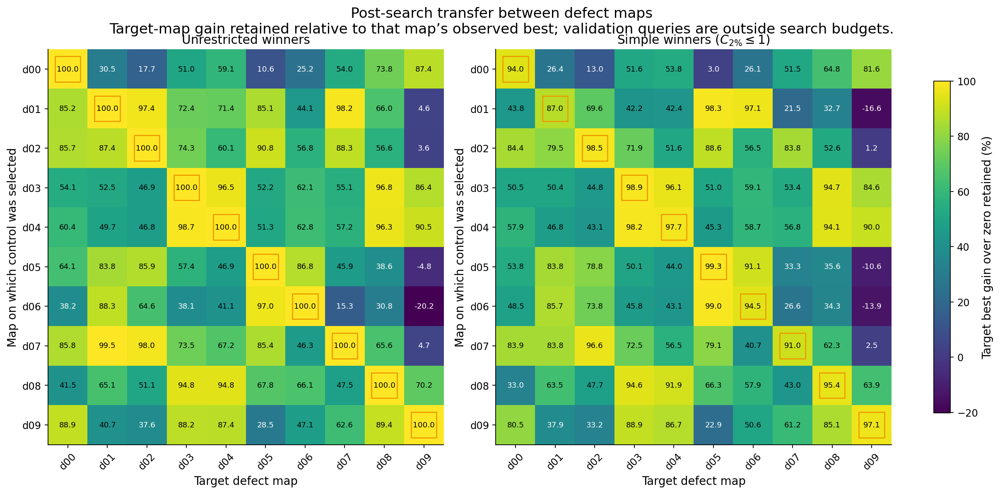

,source_target_pairs,valid_pairs
class,,
global_best,100,100
resolved_le1,100,100


,off_diagonal_pairs,median_target_gain_retained,minimum_target_gain_retained,maximum_target_gain_retained
class,,,,
global_best,90,0.626955,-0.202442,0.995422
resolved_le1,90,0.551504,-0.166348,0.989627


### Where the refined champion's gain is counted

,map_id,whole_grid_gain,interior_gain,perimeter_gain,perimeter_fraction_of_whole_gain,mostly_perimeter
0,d00,1.782430,1.372381,0.410049,0.230051,False
1,d01,2.316041,1.628633,0.687408,0.296803,False
2,d02,2.357464,2.092036,0.265428,0.112590,False
3,d03,1.695341,1.716436,-0.021096,-0.012443,False
4,d04,1.860023,1.401223,0.458800,0.246663,False
5,d05,2.826476,2.153201,0.673275,0.238203,False
6,d06,1.431675,0.898185,0.533490,0.372634,False
7,d07,1.439604,1.107412,0.332192,0.230752,False
8,d08,1.798616,1.738312,0.060303,0.033528,False
9,d09,1.750028,1.554901,0.195127,0.111500,False


In [20]:
ensemble_validation_path = VALIDATION_ROOT / "disorder_study_validation.json"
if RUN_SIMULATIONS and not RUN_FULL_REVALIDATION:
    display(Markdown("The numerical-refinement and transfer data in this section validate the frozen release controls. A fresh optimization can select different controls and does not automatically inherit their validation."))
if not ensemble_validation_path.exists():
    if not ALLOW_PARTIAL:
        raise FileNotFoundError("Final ensemble representative/transfer validation is required.")
    display(Markdown("Development run: ensemble validation is still in progress."))
else:
    ensemble_validation = json.loads(ensemble_validation_path.read_text())
    # Avoid embedding hundreds of candidate coefficient records in the notebook.
    display({k: v for k, v in ensemble_validation.items()
             if k in ("checks", "summary", "budget", "evaluation_budget", "call_ledger", "numerical_agreement", "transfer_summary")})
    numerical_summary_path = VALIDATION_ROOT / "numerical_validation_summary.json"
    numerical_summary = json.loads(numerical_summary_path.read_text())
    display({k: numerical_summary[k] for k in (
        "representative_controls", "winner_fidelity4_controls",
        "maximum_winner_full_curl_fidelity2_vs4_abs_change",
        "all_champions_increase_interior_curl")})
    extreme_rows = []
    for item in numerical_summary["high_amplitude_controls"]:
        refined = item.get("fidelity4") or item["fidelity2"]
        extreme_rows.append({
            "map": item["map_id"], "role": item["role"],
            "C2pct": item["resolved_turns"], "raw_turns": item["raw_turns"],
            "peak_Ec_8193_point_grid": item["peak_ec_8193"],
            "peak_Ec_900_simulator_samples": refined["sampled_peak_ec"],
            "refinement_fidelity": refined["fidelity"],
            "max_abs_P": refined["max_abs_P"],
            "native_guard_exceeded": refined["native_guard_exceeded"],
            "valid": refined["valid"],
        })
    display(pd.DataFrame(extreme_rows))
    display(Markdown("The amplitude audit uses an independent 8,193-point grid and the actual 900 simulator samples; the main archive's amplitude statistics use 4,097 points. These can give slightly different peak estimates. A selected control can pass refinement while lying close to the existing native |P|=10 guard; turn count alone does not measure field cost or margin to that guard."))
    validation_table = VALIDATION_ROOT / "representative_validation.csv"
    if validation_table.exists():
        display(pd.read_csv(validation_table).head(20))
    assert summary["post_search_transfer"]["available"], "Expected the completed transfer matrix."
    study_figure("ensemble_control_transfer")
    transfer = pd.read_csv(VALIDATION_ROOT / "transfer_evaluations.csv")
    display(transfer.groupby("class").agg(
        source_target_pairs=("reward", "size"), valid_pairs=("valid", "sum")))
    off_diagonal = transfer.loc[transfer.source_map != transfer.target_map]
    display(off_diagonal.groupby("class").agg(
        off_diagonal_pairs=("reward", "size"),
        median_target_gain_retained=("fraction_target_best_gain", "median"),
        minimum_target_gain_retained=("fraction_target_best_gain", "min"),
        maximum_target_gain_retained=("fraction_target_best_gain", "max")))
    boundary_path = VALIDATION_ROOT / "champion_boundary_contributions.csv"
    if not boundary_path.exists() and not ALLOW_PARTIAL:
        raise FileNotFoundError("The final champion spatial accounting table is required.")
    if boundary_path.exists():
        display(Markdown("### Where the refined champion's gain is counted"))
        boundary = pd.read_csv(boundary_path)
        display(boundary[["map_id", "whole_grid_gain", "interior_gain", "perimeter_gain",
                          "perimeter_fraction_of_whole_gain", "mostly_perimeter"]])

## 10. Reproducibility and physical-query accounting

A completed map contains 12 × 1,088 = 13,056 archived observations. Its initial
64 observations are evaluated once for each of three seed caches and copied
into four method histories. The committed optimization cost per map is
therefore **3 × 64 + 4 × 3 × 1,024 = 12,480 physical attempts**, or **124,800
for the ten-map ensemble**, if there was no interrupted uncommitted work.
Identical controls in different seed caches do not imply that those calls
were avoided. Invalid attempted evaluations still count.

The supervisor ledger records cache creation, committed new evaluations,
resume events, and failures. Any unknown work before a failed process is
disclosed separately rather than invented from saved row counts. Fixed
probes, numerical refinements, transfer queries, the original study, and the
fresh original-map reproducibility check have separate budgets. Default
notebook replay adds zero physical queries.

In [21]:
budget = study_table("budget_accounting")
display(budget[["disorder", "optimizer_runs", "observations_available_in_run_histories",
                "shared_initial_oracle_attempts_counted_once_per_seed_cache",
                "new_optimizer_oracle_attempts", "accounted_optimization_oracle_attempts",
                "accounted_invalid_optimization_attempts"]])
display(summary["execution_ledger"])
release_audit = read_json("validation/ensemble_budget_provenance_audit.json")
display(Markdown("**Recorded release construction costs.** These counts describe the completed packaged experiment, including separate smoke checks and numerical audits. They are not additional calls made by this notebook replay or the budget of a single optimizer run."))
display(pd.DataFrame([{
    "main_ensemble_physical_attempts": release_audit["physical_committed_counts"]["observations"],
    "guard_excluded_attempts": release_audit["physical_committed_counts"]["guard_exceeded"],
    "numerical_failures": release_audit["physical_committed_counts"]["numerical_failure"],
    "separate_validation_and_reproduction_attempts": release_audit["total_fresh_auxiliary_waveform_evaluations"],
    "total_recorded_fresh_physical_attempts": release_audit["total_fresh_physical_waveform_evaluations_including_auxiliary_work"],
}]))
display(pd.DataFrame(release_audit["separate_completed_fresh_auxiliary_work"])[
    ["purpose", "waveform_evaluations"]])
baseline_validation_budget = pd.DataFrame([
    {"phase": "Original-map selected controls at fidelity2", "physical_queries": len(baseline_validation["selected_candidates"])},
    {"phase": "Original-map unique winners at fidelity4", "physical_queries": sum("fidelity4" in c for c in baseline_validation["selected_candidates"])},
    {"phase": "Original-map amplitude sweep at fidelity2", "physical_queries": len(baseline_validation["amplitude_sweep"])},
    {"phase": "Archived initial projection audit at fidelity1", "physical_queries": len(projection_validation["initial_projection_rows"])},
])
display(baseline_validation_budget)
baseline_validation_budget.to_csv(TABLES / "original_validation_query_accounting.csv", index=False)
display(disorder_validation.get("diagnostic_evaluation_budget", {}))
if ensemble_validation_path.exists():
    display({k: v for k, v in ensemble_validation.items()
             if any(word in k.lower() for word in ("budget", "ledger", "call_count"))})
reproducibility_files = sorted((ROOT / "validation").glob("*reproduc*.json"))
for path in reproducibility_files:
    audit = json.loads(path.read_text())
    display(Markdown(f"### Fresh original-map reproducibility audit: `{path.name}`"))
    display({k: v for k, v in audit.items() if k != "runs"})
    if "runs" in audit:
        display(pd.DataFrame(audit["runs"])[["method", "seed", "attempted_evaluations",
                                            "all_shared_arrays_identical", "best_original_curl", "best_rerun_curl"]])
    display(Markdown("The packaged check obtained bitwise agreement in the recorded environment; exact agreement is not assumed on every platform."))
if not reproducibility_files and not ALLOW_PARTIAL:
    raise FileNotFoundError("The fresh original-map reproducibility audit must accompany the final notebook.")

,disorder,optimizer_runs,observations_available_in_run_histories,shared_initial_oracle_attempts_counted_once_per_seed_cache,new_optimizer_oracle_attempts,accounted_optimization_oracle_attempts,accounted_invalid_optimization_attempts
0,baseline,12,13056,192,12288,12480,12
1,d00,12,13056,192,12288,12480,0
2,d01,12,13056,192,12288,12480,325
3,d02,12,13056,192,12288,12480,0
4,d03,12,13056,192,12288,12480,2
5,d04,12,13056,192,12288,12480,2
6,d05,12,13056,192,12288,12480,31
7,d06,12,13056,192,12288,12480,1742
8,d07,12,13056,192,12288,12480,1
9,d08,12,13056,192,12288,12480,1


{'available': True,
 'path': 'data/disorder_ensemble/job_attempts.jsonl',
 'event_counts': {'study_started': 1,
  'job_started': 30,
  'job_complete': 30,
  'study_finished': 1},
 'initial_attempts_committed_in_ledger': 1920,
 'subsequent_attempts_committed_in_ledger': 122880,
 'attempts_with_unknown_uncommitted_work': 0,
 'unknown_work_jobs': [],
 'note': 'Archived optimization costs and supervisor ledger are reported separately. A failed process may have made additional calls before committing an archive; those cannot be inferred from row counts.'}

**Recorded release construction costs.** These counts describe the completed packaged experiment, including separate smoke checks and numerical audits. They are not additional calls made by this notebook replay or the budget of a single optimizer run.

,main_ensemble_physical_attempts,guard_excluded_attempts,numerical_failures,separate_validation_and_reproduction_attempts,total_recorded_fresh_physical_attempts
0,124800,2106,0,5196,129996


,purpose,waveform_evaluations
0,two-map four-method two-generation smoke,640
1,fresh fixed-disorder four-method seed-0 reproduction,4160
2,fresh fixed-disorder finalist validation and amplitude sweep,51
3,fresh projected initial representation validation,64
4,disorder probes and A/B/A/default-map validation,30
5,posthoc spline transfer validation,2


,phase,physical_queries
0,Original-map selected controls at fidelity2,36
1,Original-map unique winners at fidelity4,3
2,Original-map amplitude sweep at fidelity2,12
3,Archived initial projection audit at fidelity1,64


... (2 outputs left out)

### Fresh original-map reproducibility audit: `baseline_reproduction.json`

{'fresh_full_search_execution': True,
 'disorder': 'original published fixed disorder',
 'seed': 0,
 'methods': ['ga_dkl', 'gflownet_dkl', 'diffusion_dkl', 'qd_dkl'],
 'generations': 32,
 'all_trajectories_identical': True,
 'observation_budget_per_method': 1088,
 'total_archived_observations': 4352,
 'physical_query_count_sharing_one_initial_cache': 4160,
 'not_part_of_disorder_ensemble': True}

,method,seed,attempted_evaluations,all_shared_arrays_identical,best_original_curl,best_rerun_curl
0,ga_dkl,0,1088,True,11.902244,11.902244
1,gflownet_dkl,0,1088,True,11.882241,11.882241
2,diffusion_dkl,0,1088,True,11.882241,11.882241
3,qd_dkl,0,1088,True,11.902631,11.902631


The packaged check obtained bitwise agreement in the recorded environment; exact agreement is not assumed on every platform.

## 11. Read the outcomes at the level supported by the experiment

The table below is computed from the actual complete archives. It combines
each map's empirical champion, its best one-resolved-turn control, and the
two separate minimum-complexity retention thresholds. Read it together with
seed ranges, numerical refinement, and proposer provenance. Small score
differences, a common-prior winner, or a change in waveform basis should not
be promoted into a general ranking of algorithms.

A finite search budget provides measured alternatives and a reproducible
empirical Pareto front. It does not prove that larger amplitudes, additional
harmonics, longer trajectories, more generations, or different hyperparameters
could never improve the result. Cross-map transfer tests the selected
controls on these ten maps; it does not establish performance on all possible
defect realizations.

In [22]:
map_outcomes = study_table("map_outcomes")
final_table = map_outcomes.loc[map_outcomes.kind == "ensemble"].drop(columns="kind")
display(final_table)
final_table.to_csv(TABLES / "notebook_outcome_summary.csv", index=False)
print("Replay complete: analysis and figures recomputed from the selected archives.")
print(f"Full tables: {TABLES.relative_to(ROOT)}")
print(f"Study figures: {STUDY_FIGURES.relative_to(ROOT)}")
print("Exact selected controls: selected_controls.json; sampled fields: selected_waveforms.csv.gz")

Replay complete: analysis and figures recomputed from the selected archives.
Full tables: tables/study
Study figures: figures/study
Exact selected controls: selected_controls.json; sampled fields: selected_waveforms.csv.gz


,disorder,best_observed_curl,best_C2pct_le1_curl,C2pct_le1_gain_retained_pct,minimum_C_for_99.9pct_total,minimum_C_for_99pct_gain
1,d00,11.976105,11.868681,93.973183,17.000000,16.000000
2,d01,11.300988,11.000167,87.011426,24.000000,20.000000
3,d02,12.558993,12.522905,98.469210,14.000000,10.000000
4,d03,11.845486,11.826669,98.890052,9.000000,3.000000
5,d04,12.098467,12.054928,97.659202,8.000000,8.000000
6,d05,11.925031,11.904246,99.264639,11.000000,1.000000
7,d06,11.123865,11.044428,94.451432,5.000000,5.000000
8,d07,12.572277,12.442778,91.004551,18.000000,18.000000
9,d08,11.885361,11.802275,95.380580,16.000000,16.000000
10,d09,13.225440,13.174116,97.067270,15.000000,9.000000
